# ML-Assisted Prediction and Interpretation of a ZnSe/Ca$_2$CdAs$_2$/MoS$_2$ NIR Photodetector

Companion code for *SCAPS-1D and Machine Learning-Assisted Optimization of a Self-Powered ZnSe/Ca2CdAs2/MoS2 NIR PD*.

The notebook follows the four stages of the ML framework described in the manuscript:

| Stage | Section | What happens |
|---|---|---|
| 1. Data collection | §1 | Load the SCAPS-1D dataset (235,500 spectral rows) and check completeness |
| 2. Data preprocessing | §2 | Keep finite rows with both targets and $D^*>0$ (197,415 rows, 3,320 device IDs), engineer CBO/VBO, log$_{10}$-transform $D^*$, bandgap-stratified 80/20 split at device level |
| 3. Model selection | §3 | Train LR, DT, RF, GB and XGB with the tuned hyperparameters; rank them by leakage-safe grouped-CV RMSE (the selection rule); report the held-out benchmark; save the selected models |
| 4. Model implementation | §4 | Validation figures, feature importance and SHAP analysis of the selected models, which are also the models used by the optimization notebook |

**Inputs:** `photosensor_dataset.xlsx` (SCAPS-1D output) in the working directory.

Environment: Python 3.11 or newer with scikit-learn, xgboost and shap (the outputs shown were generated with Python 3.13 and scikit-learn 1.9). All random seeds are fixed (`RANDOM_STATE = 42`).


## 0. Setup

In [1]:
# If the dataset is on Google Drive, uncomment the next two lines and point DATA_PATH to it.
# from google.colab import drive
# drive.mount('/content/drive')

import os, gc, time, warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor
import shap

warnings.filterwarnings("ignore")

DATA_PATH    = "photosensor_dataset.xlsx"
OUTPUT_DIR   = "outputs"
RANDOM_STATE = 42

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Columns produced by SCAPS-1D
RAW_COLUMNS = ["Eg", "Affinity", "t", "N_A", "N_t", "Wavelength",
               "Voc", "Jsc", "QE", "Responsivity", "Detectivity"]

# The five swept device parameters define one physical device configuration (ID)
STRUCTURE_COLUMNS = ["Eg", "Affinity", "t", "N_A", "N_t"]

# Final eight predictors (six swept inputs + two engineered band offsets)
FEATURES = ["Eg", "Affinity", "t", "N_A", "N_t", "Wavelength", "CBO", "VBO"]

# Targets: Responsivity (A/W) and log10 of specific detectivity (Jones)
TARGET_R = "Responsivity"
TARGET_D = "log_Detectivity"
TARGET_NAMES = {"Responsivity": TARGET_R, "log10(Detectivity)": TARGET_D}

# Fixed window (ZnSe) and back-surface (MoS2) layer constants used for the band offsets
CHI_ZNSE = 4.09   # eV, electron affinity of ZnSe
CHI_MOS2 = 3.80   # eV, electron affinity of MoS2
EG_MOS2  = 1.62   # eV, bandgap of MoS2

BANDGAPS = [0.62, 0.79, 0.82, 0.95, 1.00]   # absorber bandgaps simulated in SCAPS

FEATURE_LABELS = {
    "Eg": r"$E_g$", "Affinity": r"$\chi_{\mathrm{Abs}}$", "t": r"$t$",
    "N_A": r"$N_A$", "N_t": r"$N_t$", "Wavelength": r"$\lambda$",
    "CBO": "CBO", "VBO": "VBO",
}
FEATURE_LABELS_MATH = {**FEATURE_LABELS, "CBO": r"$\mathrm{CBO}$", "VBO": r"$\mathrm{VBO}$"}   # used in the SHAP beeswarm plots

print("Setup complete.")

Setup complete.


### Helper functions

In [2]:
def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MSE": mse, "RMSE": np.sqrt(mse),
            "MAE": mean_absolute_error(y_true, y_pred),
            "R2": r2_score(y_true, y_pred)}


def out_path(filename):
    return os.path.join(OUTPUT_DIR, filename)


def save_tiff(fig, filename):
    # 600 dpi LZW-compressed TIFF (falls back to uncompressed if PIL kwargs are unsupported)
    path = out_path(filename)
    try:
        fig.savefig(path, dpi=600, bbox_inches="tight", format="tiff",
                    pil_kwargs={"compression": "tiff_lzw"})
    except TypeError:
        fig.savefig(path, dpi=600, bbox_inches="tight", format="tiff")
    print(f"Saved: {path}")


def set_plot_style(**overrides):
    # Publication style: serif (Times / STIX) fonts, STIX math; per-figure sizes passed as overrides
    style = {
        "font.family": "serif",
        "font.serif": ["Times New Roman", "Times", "STIXGeneral", "DejaVu Serif"],
        "mathtext.fontset": "stix",
    }
    style.update(overrides)
    mpl.rcParams.update(style)


def normalize_shap_array(values):
    # shap versions differ in the returned container (list / 3-D array); reduce to (n_rows, n_features)
    if isinstance(values, list):
        values = values[0]
    values = np.asarray(values)
    if values.ndim == 3:
        values = values[:, :, 0]
    return values


def expected_value_scalar(explainer):
    return float(np.asarray(explainer.expected_value).reshape(-1)[0])

## 1. Data collection

The dataset was generated with SCAPS-1D for the ZnSe/Ca$_2$CdAs$_2$/MoS$_2$ structure. Five absorber parameters were swept
($E_g$, $\chi_{Abs}$, $t$, $N_A$, $N_t$) and the spectral response of every configuration was recorded over 300 to 2000 nm
in 20 nm steps. Not every wavelength is meaningful for every bandgap (no absorption beyond the band edge), so some rows have
no responsivity / detectivity value.

In [3]:
df_raw = pd.read_excel(DATA_PATH)
df_raw.columns = df_raw.columns.astype(str).str.strip()

missing_columns = [c for c in RAW_COLUMNS if c not in df_raw.columns]
if missing_columns:
    raise ValueError(f"Missing columns in dataset: {missing_columns}")

for col in RAW_COLUMNS:
    df_raw[col] = pd.to_numeric(df_raw[col], errors="coerce")

print(f"Rows x columns      : {df_raw.shape[0]:,} x {df_raw.shape[1]}")
print(f"Columns             : {df_raw.columns.tolist()}")
print(f"Rows with R         : {df_raw['Responsivity'].notna().sum():,}")
print(f"Rows with D*        : {df_raw['Detectivity'].notna().sum():,}")
print(f"Rows with R and D*  : {(df_raw['Responsivity'].notna() & df_raw['Detectivity'].notna()).sum():,}")

print("\nSwept parameter levels:")
for col in STRUCTURE_COLUMNS + ["Wavelength"]:
    levels = sorted(df_raw[col].dropna().unique().tolist())
    shown = levels if len(levels) <= 10 else f"{levels[0]} ... {levels[-1]} ({len(levels)} values)"
    print(f"  {col:<10}: {shown}")

print("\nTarget availability by bandgap:")
display(
    df_raw.assign(has_both=df_raw["Responsivity"].notna() & df_raw["Detectivity"].notna())
          .groupby("Eg")
          .agg(Total_Rows=("Eg", "size"),
               Unique_Wavelengths=("Wavelength", "nunique"),
               Rows_With_Both_Targets=("has_both", "sum"))
          .assign(Coverage_pct=lambda d: 100 * d["Rows_With_Both_Targets"] / d["Total_Rows"])
          .round(2)
)

Rows x columns      : 235,500 x 11
Columns             : ['Eg', 'Affinity', 't', 'N_A', 'N_t', 'Wavelength', 'Voc', 'Jsc', 'QE', 'Responsivity', 'Detectivity']
Rows with R         : 201,600
Rows with D*        : 200,887
Rows with R and D*  : 200,887

Swept parameter levels:
  Eg        : [0.62, 0.79, 0.82, 0.95, 1.0]
  Affinity  : [4.0, 4.1, 4.2, 4.3, 4.4, 4.5]
  t         : [0.2, 0.6, 0.8, 1.2, 1.4]
  N_A       : [100000000000000, 1000000000000000, 10000000000000000, 100000000000000000, 1000000000000000000]
  N_t       : [1000000000000, 10000000000000, 100000000000000, 1000000000000000, 10000000000000000]
  Wavelength: 300 ... 2000 (86 values)

Target availability by bandgap:


,Total_Rows,Unique_Wavelengths,Rows_With_Both_Targets,Coverage_pct
Eg,,,,
0.62,64500,86,36550,56.67
0.79,48750,65,45435,93.20
0.82,46500,62,43152,92.80
0.95,39000,52,39000,100.00
1.00,36750,49,36750,100.00


## 2. Data preprocessing

1. Every unique ($E_g$, $\chi_{Abs}$, $t$, $N_A$, $N_t$) combination receives a `Structure_ID`; all wavelengths of one device share the ID.
2. Rows are kept only when all predictors and both targets are present and finite, and $D^* > 0$.
3. Two physics-informed features are added: the conduction-band offset at the ZnSe/absorber interface,
   $\mathrm{CBO} = \chi_{Abs} - \chi_{ZnSe}$, and the valence-band offset at the absorber/MoS$_2$ interface,
   $\mathrm{VBO} = (\chi_{MoS_2} + E_{g,MoS_2}) - (\chi_{Abs} + E_g)$.
4. $D^*$ is modelled as $\log_{10}(D^*)$ and back-transformed as $D^* = 10^{\log_{10}D^*}$ where needed.

In [4]:
df = df_raw.copy()

# 1. Device identifier (assigned on the full dataset, before any filtering)
df["Structure_ID"] = df.groupby(STRUCTURE_COLUMNS, sort=False).ngroup()

# 2. Supervised-learning filter
required = STRUCTURE_COLUMNS + ["Wavelength", "Responsivity", "Detectivity"]
df_ml = df.dropna(subset=required)
df_ml = df_ml[df_ml["Detectivity"] > 0].copy()

# 3. Physics-informed interface features
df_ml["CBO"] = df_ml["Affinity"] - CHI_ZNSE
df_ml["VBO"] = CHI_MOS2 - df_ml["Affinity"] + EG_MOS2 - df_ml["Eg"]

# 4. Log-scale detectivity target
df_ml["log_Detectivity"] = np.log10(df_ml["Detectivity"])

# Final clean table (finite values only)
value_columns = FEATURES + ["Responsivity", "Detectivity", "log_Detectivity"]
df_clean = df_ml[["Structure_ID"] + value_columns].dropna()
df_clean = df_clean.loc[np.isfinite(df_clean[value_columns]).all(axis=1)].reset_index(drop=True)

assert df_clean.duplicated(subset=["Structure_ID", "Wavelength"]).sum() == 0
assert (df_clean.groupby("Structure_ID")["Eg"].nunique() == 1).all()

print(f"Rows before filtering : {len(df):,}")
print(f"Rows after filtering  : {len(df_clean):,}")
print(f"Device configurations : {df_clean['Structure_ID'].nunique():,}")
print(f"Predictors ({len(FEATURES)})        : {FEATURES}")
print(f"Targets               : {TARGET_R}, {TARGET_D}")

print("\nRows and devices per bandgap:")
display(df_clean.groupby("Eg").agg(Rows=("Eg", "size"), Devices=("Structure_ID", "nunique")))

print("\nFeature ranges:")
display(df_clean[FEATURES].describe().T[["min", "max", "mean", "std"]])

Rows before filtering : 235,500
Rows after filtering  : 197,415
Device configurations : 3,320
Predictors (8)        : ['Eg', 'Affinity', 't', 'N_A', 'N_t', 'Wavelength', 'CBO', 'VBO']
Targets               : Responsivity, log_Detectivity

Rows and devices per bandgap:


,Rows,Devices
Eg,,
0.62,36164,425
0.79,44872,699
0.82,42542,696
0.95,38372,750
1.00,35465,750



Feature ranges:


,min,max,mean,std
Eg,6.200000e-01,1.000000e+00,8.341484e-01,1.282086e-01
Affinity,4.000000e+00,4.500000e+00,4.277620e+00,1.653206e-01
t,2.000000e-01,1.400000e+00,8.245534e-01,4.262370e-01
N_A,1.000000e+14,1.000000e+18,2.327074e+17,3.993227e+17
N_t,1.000000e+12,1.000000e+16,2.227796e+15,3.911322e+15
Wavelength,3.000000e+02,2.000000e+03,9.079389e+02,3.855959e+02
CBO,-9.000000e-02,4.100000e-01,1.876197e-01,1.653206e-01
VBO,-8.000000e-02,8.000000e-01,3.082319e-01,1.869387e-01


### Bandgap-stratified, device-level 80/20 split

The split is performed on device IDs (not rows) and stratified by $E_g$, so every wavelength of a device stays in one subset
and each bandgap keeps a test fraction close to 20%.

In [5]:
structure_table = (
    df_clean[["Structure_ID"] + STRUCTURE_COLUMNS]
    .drop_duplicates(subset="Structure_ID")
    .reset_index(drop=True)
)

train_structures, test_structures = train_test_split(
    structure_table, test_size=0.20, random_state=RANDOM_STATE, stratify=structure_table["Eg"]
)

train_ids = set(train_structures["Structure_ID"])
test_ids  = set(test_structures["Structure_ID"])
assert not (train_ids & test_ids), "Structure_ID leakage between train and test"

train_df = df_clean[df_clean["Structure_ID"].isin(train_ids)].reset_index(drop=True)
test_df  = df_clean[df_clean["Structure_ID"].isin(test_ids)].reset_index(drop=True)
assert len(train_df) + len(test_df) == len(df_clean)

X_train, X_test = train_df[FEATURES].copy(), test_df[FEATURES].copy()
y_train = {name: train_df[col].copy() for name, col in TARGET_NAMES.items()}
y_test  = {name: test_df[col].copy()  for name, col in TARGET_NAMES.items()}

print(f"Train : {len(train_ids):,} devices, {len(train_df):,} rows ({100*len(train_df)/len(df_clean):.2f}%)")
print(f"Test  : {len(test_ids):,} devices, {len(test_df):,} rows ({100*len(test_df)/len(df_clean):.2f}%)")

split_balance = (
    pd.concat([train_df.assign(Subset="Train"), test_df.assign(Subset="Test")])
      .groupby(["Eg", "Subset"])
      .agg(Devices=("Structure_ID", "nunique"), Rows=("Eg", "size"))
      .unstack("Subset")
)
split_balance[("Test_fraction_%", "Devices")] = 100 * split_balance[("Devices", "Test")] / split_balance["Devices"].sum(axis=1)
split_balance[("Test_fraction_%", "Rows")]    = 100 * split_balance[("Rows", "Test")]    / split_balance["Rows"].sum(axis=1)

print("\nBandgap balance of the split:")
display(split_balance.round(2))

Train : 2,656 devices, 157,928 rows (80.00%)
Test  : 664 devices, 39,487 rows (20.00%)

Bandgap balance of the split:


Devices        Rows        Test_fraction_%       
Subset    Test Train  Test  Train         Devices   Rows
Eg                                                      
0.62        85   340  7232  28932           20.00  20.00
0.79       140   559  8987  35885           20.03  20.03
0.82       139   557  8499  34043           19.97  19.98
0.95       150   600  7681  30691           20.00  20.02
1.00       150   600  7088  28377           20.00  19.99

## 3. Model selection

Five regressors are compared per target. Hyperparameters were tuned beforehand with `RandomizedSearchCV`
(3-fold `StratifiedGroupKFold`, grouped by `Structure_ID`, stratified by $E_g$, scored by RMSE; see the companion tuning
notebook); the tuned values are used here directly.

**Selection rule.** Each tuned model is scored by repeated, device-grouped, bandgap-stratified cross-validation on the
training devices only: 5 folds × 3 random seeds = 15 validation folds per model. Whole devices are assigned to folds
(balanced within each bandgap, fixed random seeds), so no spectral row of a validation device is seen during fitting, and
the fold assignment does not depend on library internals. The model with the lowest mean CV RMSE is selected for each
target. The untouched test devices are used once afterwards, to report the held-out benchmark of all models; they play no
part in the selection.

| Model | Search space | Selected ($R$) | Selected (log$_{10}D^*$) |
|---|---|---|---|
| LR | none (StandardScaler + LinearRegression) | – | – |
| DT | max_depth {3, 5, 10, None}; min_samples_split {2, 5, 10}; min_samples_leaf {1, 2, 4} | None / 5 / 2 | None / 2 / 2 |
| RF | n_estimators {100, 200}; max_depth {3, 5, 10, None}; min_samples_split {2, 5} | 200 / None / 2 | 200 / None / 2 |
| GB | n_estimators {100, 200}; learning_rate {0.01, 0.05, 0.1, 0.2}; max_depth {3, 5, 10} | 200 / 0.05 / 10 | 100 / 0.10 / 10 |
| XGB | n_estimators {100, 200}; learning_rate {0.01, 0.1, 0.2}; max_depth {3, 6, 10}; subsample {0.8, 1.0} | 200 / 0.20 / 10 / 0.8 | 200 / 0.20 / 6 / 1.0 |

In [6]:
def xgb(**kw):
    return XGBRegressor(objective="reg:squarederror", eval_metric="rmse", tree_method="hist",
                        random_state=RANDOM_STATE, n_jobs=-1, verbosity=0, **kw)

MODELS_BY_TARGET = {
    "Responsivity": {
        "LR":  Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]),
        "DT":  DecisionTreeRegressor(max_depth=None, min_samples_split=5, min_samples_leaf=2, random_state=RANDOM_STATE),
        "RF":  RandomForestRegressor(n_estimators=200, max_depth=None, min_samples_split=2, random_state=RANDOM_STATE, n_jobs=-1),
        "GB":  GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=10, random_state=RANDOM_STATE),
        "XGB": xgb(n_estimators=200, learning_rate=0.20, max_depth=10, subsample=0.80),
    },
    "log10(Detectivity)": {
        "LR":  Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]),
        "DT":  DecisionTreeRegressor(max_depth=None, min_samples_split=2, min_samples_leaf=2, random_state=RANDOM_STATE),
        "RF":  RandomForestRegressor(n_estimators=200, max_depth=None, min_samples_split=2, random_state=RANDOM_STATE, n_jobs=-1),
        "GB":  GradientBoostingRegressor(n_estimators=100, learning_rate=0.10, max_depth=10, random_state=RANDOM_STATE),
        "XGB": xgb(n_estimators=200, learning_rate=0.20, max_depth=6, subsample=1.00),
    },
}

# --- Repeated device-grouped, bandgap-stratified cross-validation on the training devices (selection criterion) ---
N_CV_FOLDS = 5
CV_SEEDS = [42, 123, 2026]


def device_folds(df, n_splits, seed):
    # Whole devices are dealt into folds, separately within each bandgap, using a fixed RNG.
    devices = df[["Structure_ID", "Eg"]].drop_duplicates("Structure_ID").sort_values("Structure_ID")
    rng = np.random.default_rng(seed)
    fold_of = {}
    for _, sub in devices.groupby("Eg"):
        for k, sid in enumerate(rng.permutation(sub["Structure_ID"].to_numpy())):
            fold_of[sid] = k % n_splits
    fold = df["Structure_ID"].map(fold_of).to_numpy()
    return [(np.where(fold != k)[0], np.where(fold == k)[0]) for k in range(n_splits)]


cv_fold_records = []
for seed in CV_SEEDS:
    folds = device_folds(train_df, N_CV_FOLDS, seed)
    for k, (fit_idx, val_idx) in enumerate(folds):
        assert not (set(train_df.loc[fit_idx, "Structure_ID"]) & set(train_df.loc[val_idx, "Structure_ID"]))
    for target, models in MODELS_BY_TARGET.items():
        y = y_train[target]
        for name, template in models.items():
            start = time.time()
            for k, (fit_idx, val_idx) in enumerate(folds):
                model = clone(template).fit(X_train.iloc[fit_idx], y.iloc[fit_idx])
                rmse = np.sqrt(mean_squared_error(y.iloc[val_idx], model.predict(X_train.iloc[val_idx])))
                cv_fold_records.append({"Seed": seed, "Fold": k, "Target": target, "Model": name, "RMSE": rmse})
                del model
            print(f"seed {seed}  {target:<20} {name:<4} mean fold RMSE = "
                  f"{np.mean([r['RMSE'] for r in cv_fold_records[-N_CV_FOLDS:]]):.6f}  ({time.time() - start:.0f} s)")
    gc.collect()

cv_folds_df = pd.DataFrame(cv_fold_records)
cv_results_df = (cv_folds_df.groupby(["Target", "Model"])["RMSE"]
                 .agg(CV_RMSE="mean", CV_RMSE_std="std", N_folds="count").reset_index())
cv_results_df["CV_RMSE_se"] = cv_results_df["CV_RMSE_std"] / np.sqrt(cv_results_df["N_folds"])
cv_results_df = cv_results_df.sort_values(["Target", "CV_RMSE"]).reset_index(drop=True)
CV_SELECTED = cv_results_df.loc[cv_results_df.groupby("Target")["CV_RMSE"].idxmin()].set_index("Target")["Model"].to_dict()

print("\nRepeated grouped-CV ranking (selection criterion, mean over 15 validation folds):")
display(cv_results_df)
print("\nMean CV RMSE per repeat (seed):")
display(cv_folds_df.groupby(["Target", "Seed", "Model"])["RMSE"].mean().unstack("Model"))
print("Selected models:", CV_SELECTED)

seed 42  Responsivity         LR   mean fold RMSE = 0.215539  (0 s)


seed 42  Responsivity         DT   mean fold RMSE = 0.000454  (2 s)


seed 42  Responsivity         RF   mean fold RMSE = 0.000932  (137 s)


seed 42  Responsivity         GB   mean fold RMSE = 0.001788  (186 s)


seed 42  Responsivity         XGB  mean fold RMSE = 0.000911  (4 s)
seed 42  log10(Detectivity)   LR   mean fold RMSE = 0.967292  (0 s)


seed 42  log10(Detectivity)   DT   mean fold RMSE = 0.179161  (2 s)


... (21 outputs left out)

,Target,Model,CV_RMSE,CV_RMSE_std,N_folds,CV_RMSE_se
0,Responsivity,DT,0.000623,0.000474,15,0.000123
1,Responsivity,XGB,0.000783,0.000369,15,0.000095
2,Responsivity,RF,0.000809,0.000508,15,0.000131
3,Responsivity,GB,0.001136,0.001275,15,0.000329
4,Responsivity,LR,0.215538,0.006203,15,0.001602
5,log10(Detectivity),GB,0.152808,0.153703,15,0.039686
6,log10(Detectivity),RF,0.160423,0.149759,15,0.038668
7,log10(Detectivity),XGB,0.168069,0.160461,15,0.041431
8,log10(Detectivity),DT,0.182945,0.141161,15,0.036448
9,log10(Detectivity),LR,0.968374,0.044624,15,0.011522



Mean CV RMSE per repeat (seed):


Model                          DT        GB        LR        RF       XGB
Target             Seed                                                  
Responsivity       42    0.000454  0.001788  0.215539  0.000932  0.000911
                   123   0.000714  0.000832  0.215611  0.000797  0.000765
                   2026  0.000700  0.000788  0.215465  0.000698  0.000673
log10(Detectivity) 42    0.179161  0.152157  0.967292  0.160561  0.155694
                   123   0.181825  0.159238  0.968570  0.162906  0.149972
                   2026  0.187847  0.147030  0.969261  0.157803  0.198541

Selected models: {'Responsivity': 'DT', 'log10(Detectivity)': 'GB'}


In [7]:
# --- Fit every model on the full training set and benchmark on the held-out test devices ---
selected_models = {}
test_predictions = {t: {} for t in MODELS_BY_TARGET}
records = []

for target, models in MODELS_BY_TARGET.items():
    for name, template in models.items():
        start = time.time()
        model = clone(template).fit(X_train, y_train[target])
        elapsed = time.time() - start

        pred_train, pred_test = model.predict(X_train), model.predict(X_test)
        test_predictions[target][name] = pred_test
        if name == CV_SELECTED[target]:
            selected_models[target] = model
        else:
            del model            # only the selected models are carried forward

        for subset, y_true, y_pred in [("Train", y_train[target], pred_train), ("Test", y_test[target], pred_test)]:
            records.append({"Target": target, "Model": name, "Dataset": subset,
                            **regression_metrics(y_true, y_pred), "Training_Time_sec": elapsed})
        print(f"{target:<20} {name:<4} test R2 = {records[-1]['R2']:.6f}  test RMSE = {records[-1]['RMSE']:.3e}  ({elapsed:.1f} s)")
gc.collect()

metrics_df = pd.DataFrame(records)
metric_cols = ["Target", "Model", "MSE", "RMSE", "MAE", "R2", "Training_Time_sec"]

test_metrics_df  = metrics_df[metrics_df["Dataset"] == "Test"].sort_values(["Target", "RMSE"]).reset_index(drop=True)[metric_cols]
train_metrics_df = metrics_df[metrics_df["Dataset"] == "Train"].sort_values(["Target", "RMSE"]).reset_index(drop=True)[metric_cols]

# Combined table: selection criterion (grouped CV) next to the held-out benchmark
benchmark_df = (cv_results_df[["Target", "Model", "CV_RMSE", "CV_RMSE_se"]]
                .merge(test_metrics_df[["Target", "Model", "MSE", "RMSE", "MAE", "R2"]], on=["Target", "Model"])
                .rename(columns={"MSE": "Test_MSE", "RMSE": "Test_RMSE", "MAE": "Test_MAE", "R2": "Test_R2"})
                .sort_values(["Target", "CV_RMSE"]).reset_index(drop=True))
benchmark_df["Selected"] = [CV_SELECTED[t] == m for t, m in zip(benchmark_df["Target"], benchmark_df["Model"])]

print("\nSelection criterion (mean repeated grouped-CV RMSE ± SE) and held-out benchmark:")
display(benchmark_df)
print("\nTest-set performance (sorted by test RMSE within target):")
display(test_metrics_df)
print("\nTraining-set performance:")
display(train_metrics_df)

Responsivity         LR   test R2 = 0.516802  test RMSE = 2.138e-01  (0.0 s)


Responsivity         DT   test R2 = 0.999996  test RMSE = 6.490e-04  (0.4 s)


Responsivity         RF   test R2 = 0.999998  test RMSE = 4.350e-04  (33.4 s)


Responsivity         GB   test R2 = 0.999994  test RMSE = 7.219e-04  (47.2 s)


Responsivity         XGB  test R2 = 0.999998  test RMSE = 4.427e-04  (0.6 s)
log10(Detectivity)   LR   test R2 = 0.644687  test RMSE = 9.308e-01  (0.0 s)


log10(Detectivity)   DT   test R2 = 0.996290  test RMSE = 9.512e-02  (0.4 s)


... (4 outputs left out)


Test-set performance (sorted by test RMSE within target):


,Target,Model,MSE,RMSE,MAE,R2,Training_Time_sec
0,Responsivity,RF,1.892383e-07,0.000435,0.000039,0.999998,33.375113
1,Responsivity,XGB,1.959667e-07,0.000443,0.000230,0.999998,0.620354
2,Responsivity,DT,4.211390e-07,0.000649,0.000037,0.999996,0.404896
3,Responsivity,GB,5.211549e-07,0.000722,0.000299,0.999994,47.228332
4,Responsivity,LR,4.571704e-02,0.213815,0.154937,0.516802,0.045382
5,log10(Detectivity),XGB,6.950629e-03,0.083370,0.033185,0.997150,0.539583
6,log10(Detectivity),RF,7.223445e-03,0.084991,0.015569,0.997038,31.975579
7,log10(Detectivity),GB,7.505751e-03,0.086636,0.020124,0.996922,22.571472
8,log10(Detectivity),DT,9.048147e-03,0.095122,0.018288,0.996290,0.386061
9,log10(Detectivity),LR,8.664502e-01,0.930833,0.572426,0.644687,0.041348



Training-set performance:


,Target,Model,MSE,RMSE,MAE,R2,Training_Time_sec
0,Responsivity,RF,4.992870e-08,0.000223,0.000012,0.999999,33.375113
1,Responsivity,XGB,1.421343e-07,0.000377,0.000215,0.999999,0.620354
2,Responsivity,DT,1.506976e-07,0.000388,0.000014,0.999998,0.404896
3,Responsivity,GB,3.667611e-07,0.000606,0.000286,0.999996,47.228332
4,Responsivity,LR,4.634262e-02,0.215273,0.154853,0.515663,0.045382
5,log10(Detectivity),GB,2.028889e-04,0.014244,0.008788,0.999916,22.571472
6,log10(Detectivity),RF,4.691746e-04,0.021660,0.002091,0.999805,31.975579
7,log10(Detectivity),DT,9.972944e-04,0.031580,0.003498,0.999585,0.386061
8,log10(Detectivity),XGB,1.639812e-03,0.040495,0.022545,0.999318,0.539583
9,log10(Detectivity),LR,9.362907e-01,0.967621,0.590621,0.610464,0.041348


### Final (CV-selected) models

The models with the lowest mean repeated grouped-CV RMSE are the final models for the rest of this notebook and for the companion
optimization notebook (`photosensor_optimization_clean.ipynb`), which loads the two files saved here.

In [8]:
final_models = selected_models            # e.g. {"Responsivity": DecisionTreeRegressor, "log10(Detectivity)": GradientBoostingRegressor}
for target, model in final_models.items():
    print(f"{target:<20} -> {CV_SELECTED[target]:<4} ({type(model).__name__})")

display(benchmark_df[benchmark_df["Selected"]].drop(columns="Selected").reset_index(drop=True))

joblib.dump(final_models["Responsivity"],       out_path("Best_Model_Responsivity.pkl"))
joblib.dump(final_models["log10(Detectivity)"], out_path("Best_Model_log10_Detectivity.pkl"))
print("Saved: Best_Model_Responsivity.pkl, Best_Model_log10_Detectivity.pkl")

Responsivity         -> DT   (DecisionTreeRegressor)
log10(Detectivity)   -> GB   (GradientBoostingRegressor)


,Target,Model,CV_RMSE,CV_RMSE_se,Test_MSE,Test_RMSE,Test_MAE,Test_R2
0,Responsivity,DT,0.000623,0.000123,4.211390e-07,0.000649,0.000037,0.999996
1,log10(Detectivity),GB,0.152808,0.039686,7.505751e-03,0.086636,0.020124,0.996922


Saved: Best_Model_Responsivity.pkl, Best_Model_log10_Detectivity.pkl


## 4. Model implementation

### 4.1 Predictions of the final models

The CV-selected models are used for everything that follows: actual-vs-predicted plots, spectral validation on unseen
devices, impurity-based feature importance and SHAP interpretation.

In [9]:
X_train_f = X_train.astype(np.float32)          # float32 copies are used in the SHAP stage
X_test_f  = X_test.astype(np.float32)
y_train_f = {t: y.astype(np.float32) for t, y in y_train.items()}
y_test_f  = {t: y.astype(np.float32) for t, y in y_test.items()}

final_predictions, final_records = {}, []
for target, model in final_models.items():
    final_predictions[target] = {"Train": model.predict(X_train), "Test": model.predict(X_test)}
    for subset, y_true in [("Train", y_train[target]), ("Test", y_test[target])]:
        final_records.append({"Target": target, "Dataset": subset, "Model": CV_SELECTED[target],
                              **regression_metrics(y_true, final_predictions[target][subset])})

final_metrics = pd.DataFrame(final_records)
print("Final model performance:")
display(final_metrics)

Final model performance:


,Target,Dataset,Model,MSE,RMSE,MAE,R2
0,Responsivity,Train,DT,1.506976e-07,0.000388,0.000014,0.999998
1,Responsivity,Test,DT,4.211390e-07,0.000649,0.000037,0.999996
2,log10(Detectivity),Train,GB,2.028889e-04,0.014244,0.008788,0.999916
3,log10(Detectivity),Test,GB,7.505751e-03,0.086636,0.020124,0.996922


### 4.2 Actual vs predicted (train and test)

Saved: outputs/Actual_vs_Predicted_Responsivity.tiff


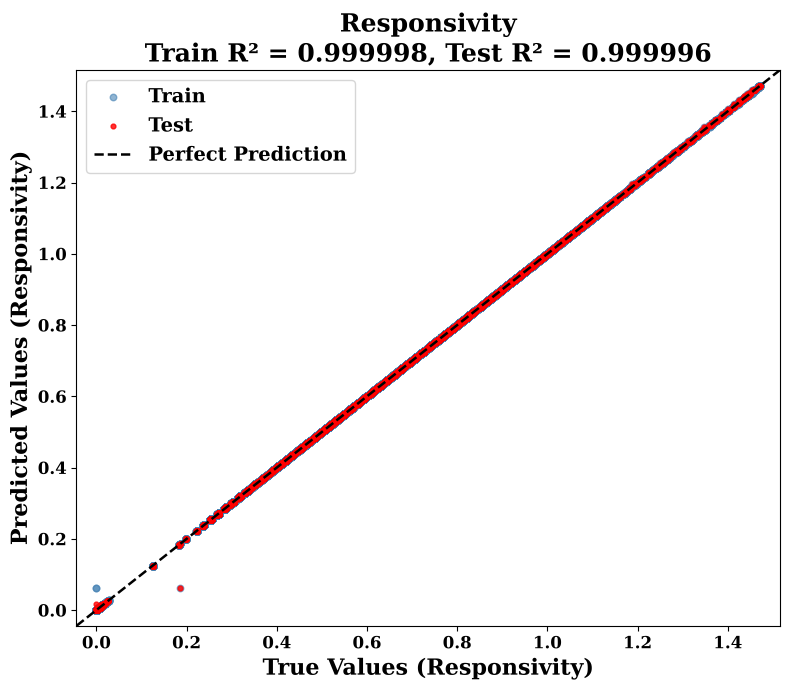

Saved: outputs/Actual_vs_Predicted_log10_Detectivity.tiff


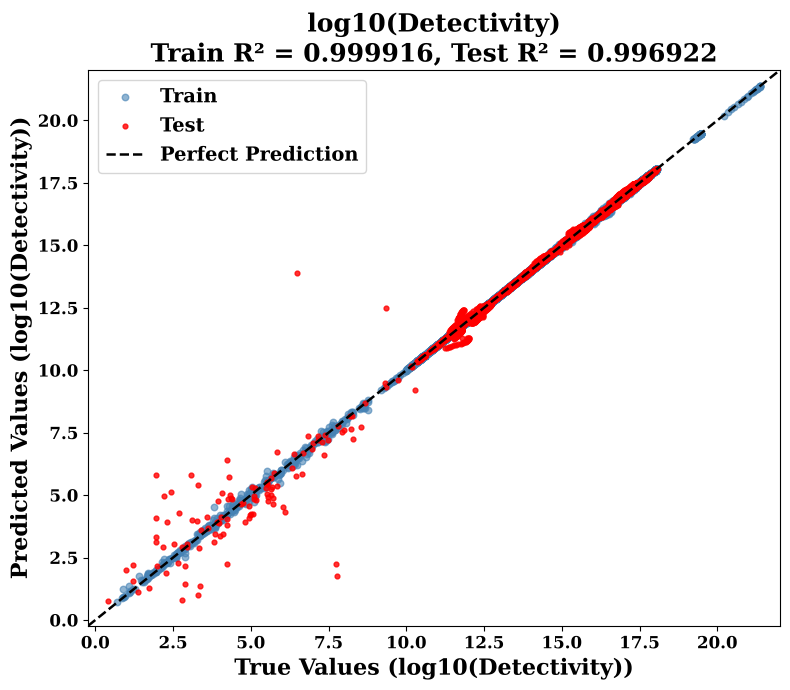

In [10]:
mpl.rcParams.update({"font.family": "serif", "font.weight": "bold"})

def plot_actual_vs_predicted(target, axis_label, filename):
    y_tr, y_te = np.array(y_train_f[target]), np.array(y_test_f[target])
    p_tr, p_te = final_predictions[target]["Train"], final_predictions[target]["Test"]

    lo = min(y_tr.min(), y_te.min(), p_tr.min(), p_te.min())
    hi = max(y_tr.max(), y_te.max(), p_tr.max(), p_te.max())
    pad = 0.03 * (hi - lo)
    lo, hi = lo - pad, hi + pad

    plt.figure(figsize=(8, 7))
    plt.scatter(y_tr, p_tr, color="steelblue", alpha=0.6, s=22, label="Train")
    plt.scatter(y_te, p_te, color="red", alpha=0.8, s=12, label="Test")
    plt.plot([lo, hi], [lo, hi], "k--", linewidth=1.8, label="Perfect Prediction")
    plt.title(f"{target}\nTrain R² = {r2_score(y_tr, p_tr):.6f}, Test R² = {r2_score(y_te, p_te):.6f}",
              fontsize=18, fontweight="bold")
    plt.xlabel(f"True Values ({axis_label})", fontsize=16, fontweight="bold")
    plt.ylabel(f"Predicted Values ({axis_label})", fontsize=16, fontweight="bold")
    plt.xlim(lo, hi); plt.ylim(lo, hi)
    for text in plt.legend(fontsize=14, frameon=True).get_texts():
        text.set_fontweight("bold")
    ax = plt.gca()
    ax.tick_params(axis="both", labelsize=12)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight("bold")
    plt.grid(False)
    plt.tight_layout()
    plt.savefig(out_path(filename), dpi=600, bbox_inches="tight", format="tiff")
    print(f"Saved: {out_path(filename)}")
    plt.show()

plot_actual_vs_predicted("Responsivity", "Responsivity", "Actual_vs_Predicted_Responsivity.tiff")
plot_actual_vs_predicted("log10(Detectivity)", "log10(Detectivity)", "Actual_vs_Predicted_log10_Detectivity.tiff")

### 4.3 Spectral validation on unseen devices

For each bandgap, the test device with the most complete spectrum is selected and its actual and predicted spectral
response is compared across all wavelengths.

In [11]:
from matplotlib.lines import Line2D
from matplotlib.ticker import LogLocator, LogFormatterMathtext, NullFormatter

spectral_df = test_df.copy()
spectral_df["Predicted_Responsivity"]    = final_predictions["Responsivity"]["Test"]
spectral_df["Predicted_log_Detectivity"] = final_predictions["log10(Detectivity)"]["Test"]
spectral_df["Predicted_Detectivity"]     = 10.0 ** spectral_df["Predicted_log_Detectivity"]
spectral_df["Eg_round"] = spectral_df["Eg"].round(2)

# One test device per bandgap: most wavelengths, then widest span, then lowest ID
structure_summary = (
    spectral_df.groupby(["Eg_round", "Structure_ID"], as_index=False)
    .agg(Unique_Wavelengths=("Wavelength", "nunique"), Min_Wavelength_nm=("Wavelength", "min"),
         Max_Wavelength_nm=("Wavelength", "max"), Affinity_eV=("Affinity", "first"),
         Thickness_um=("t", "first"), N_A_cm3=("N_A", "first"), N_t_cm3=("N_t", "first"),
         CBO_eV=("CBO", "first"), VBO_eV=("VBO", "first"))
)
structure_summary["Wavelength_Span_nm"] = structure_summary["Max_Wavelength_nm"] - structure_summary["Min_Wavelength_nm"]

selected_structures = (
    structure_summary.sort_values(["Eg_round", "Unique_Wavelengths", "Wavelength_Span_nm", "Structure_ID"],
                                  ascending=[True, False, False, True])
    .groupby("Eg_round", group_keys=False).head(1)
    .sort_values("Eg_round").reset_index(drop=True)
)
selected_spectral_df = (
    spectral_df[spectral_df["Structure_ID"].isin(selected_structures["Structure_ID"])]
    .sort_values(["Eg_round", "Wavelength"]).reset_index(drop=True)
)

bandgap_metrics = []
for eg in BANDGAPS:
    sub = selected_spectral_df[np.isclose(selected_spectral_df["Eg_round"], eg)]
    bandgap_metrics.append({
        "Eg_eV": eg, "Structure_ID": sub["Structure_ID"].iloc[0], "Spectral_Points": sub["Wavelength"].nunique(),
        "Responsivity_R2":   r2_score(sub["Responsivity"], sub["Predicted_Responsivity"]),
        "Responsivity_RMSE": np.sqrt(mean_squared_error(sub["Responsivity"], sub["Predicted_Responsivity"])),
        "Responsivity_MAE":  mean_absolute_error(sub["Responsivity"], sub["Predicted_Responsivity"]),
        "logD_R2":   r2_score(sub["log_Detectivity"], sub["Predicted_log_Detectivity"]),
        "logD_RMSE": np.sqrt(mean_squared_error(sub["log_Detectivity"], sub["Predicted_log_Detectivity"])),
        "logD_MAE":  mean_absolute_error(sub["log_Detectivity"], sub["Predicted_log_Detectivity"]),
    })
bandgap_metrics = pd.DataFrame(bandgap_metrics)

print("Selected unseen devices:")
display(selected_structures)
print("\nSpectral metrics per device:")
display(bandgap_metrics)

Selected unseen devices:


,Eg_round,Structure_ID,Unique_Wavelengths,Min_Wavelength_nm,Max_Wavelength_nm,Affinity_eV,Thickness_um,N_A_cm3,N_t_cm3,CBO_eV,VBO_eV,Wavelength_Span_nm
0,0.62,448,86,300,2000,4.3,0.8,1000000000000000000,1000000000000000,0.21,0.50,1700
1,0.79,778,65,300,1580,4.0,0.6,100000000000000,1000000000000000,-0.09,0.63,1280
2,0.82,1525,62,300,1520,4.0,0.6,100000000000000,1000000000000,-0.09,0.60,1220
3,0.95,2250,52,300,1320,4.0,0.2,100000000000000,1000000000000,-0.09,0.47,1020
4,1.00,3011,49,300,1260,4.0,0.2,10000000000000000,10000000000000,-0.09,0.42,960



Spectral metrics per device:


,Eg_eV,Structure_ID,Spectral_Points,Responsivity_R2,Responsivity_RMSE,Responsivity_MAE,logD_R2,logD_RMSE,logD_MAE
0,0.62,448,86,1.000000,0.000046,0.000024,0.999684,0.019095,0.013888
1,0.79,778,65,0.997132,0.000033,0.000021,0.996480,0.024644,0.010371
2,0.82,1525,62,0.999985,0.000010,0.000009,0.999989,0.001346,0.000845
3,0.95,2250,52,1.000000,0.000007,0.000003,0.999898,0.014435,0.007632
4,1.00,3011,49,1.000000,0.000005,0.000002,0.999974,0.011235,0.008125


Saved: outputs/Spectral_Responsivity_5Bandgaps.tiff


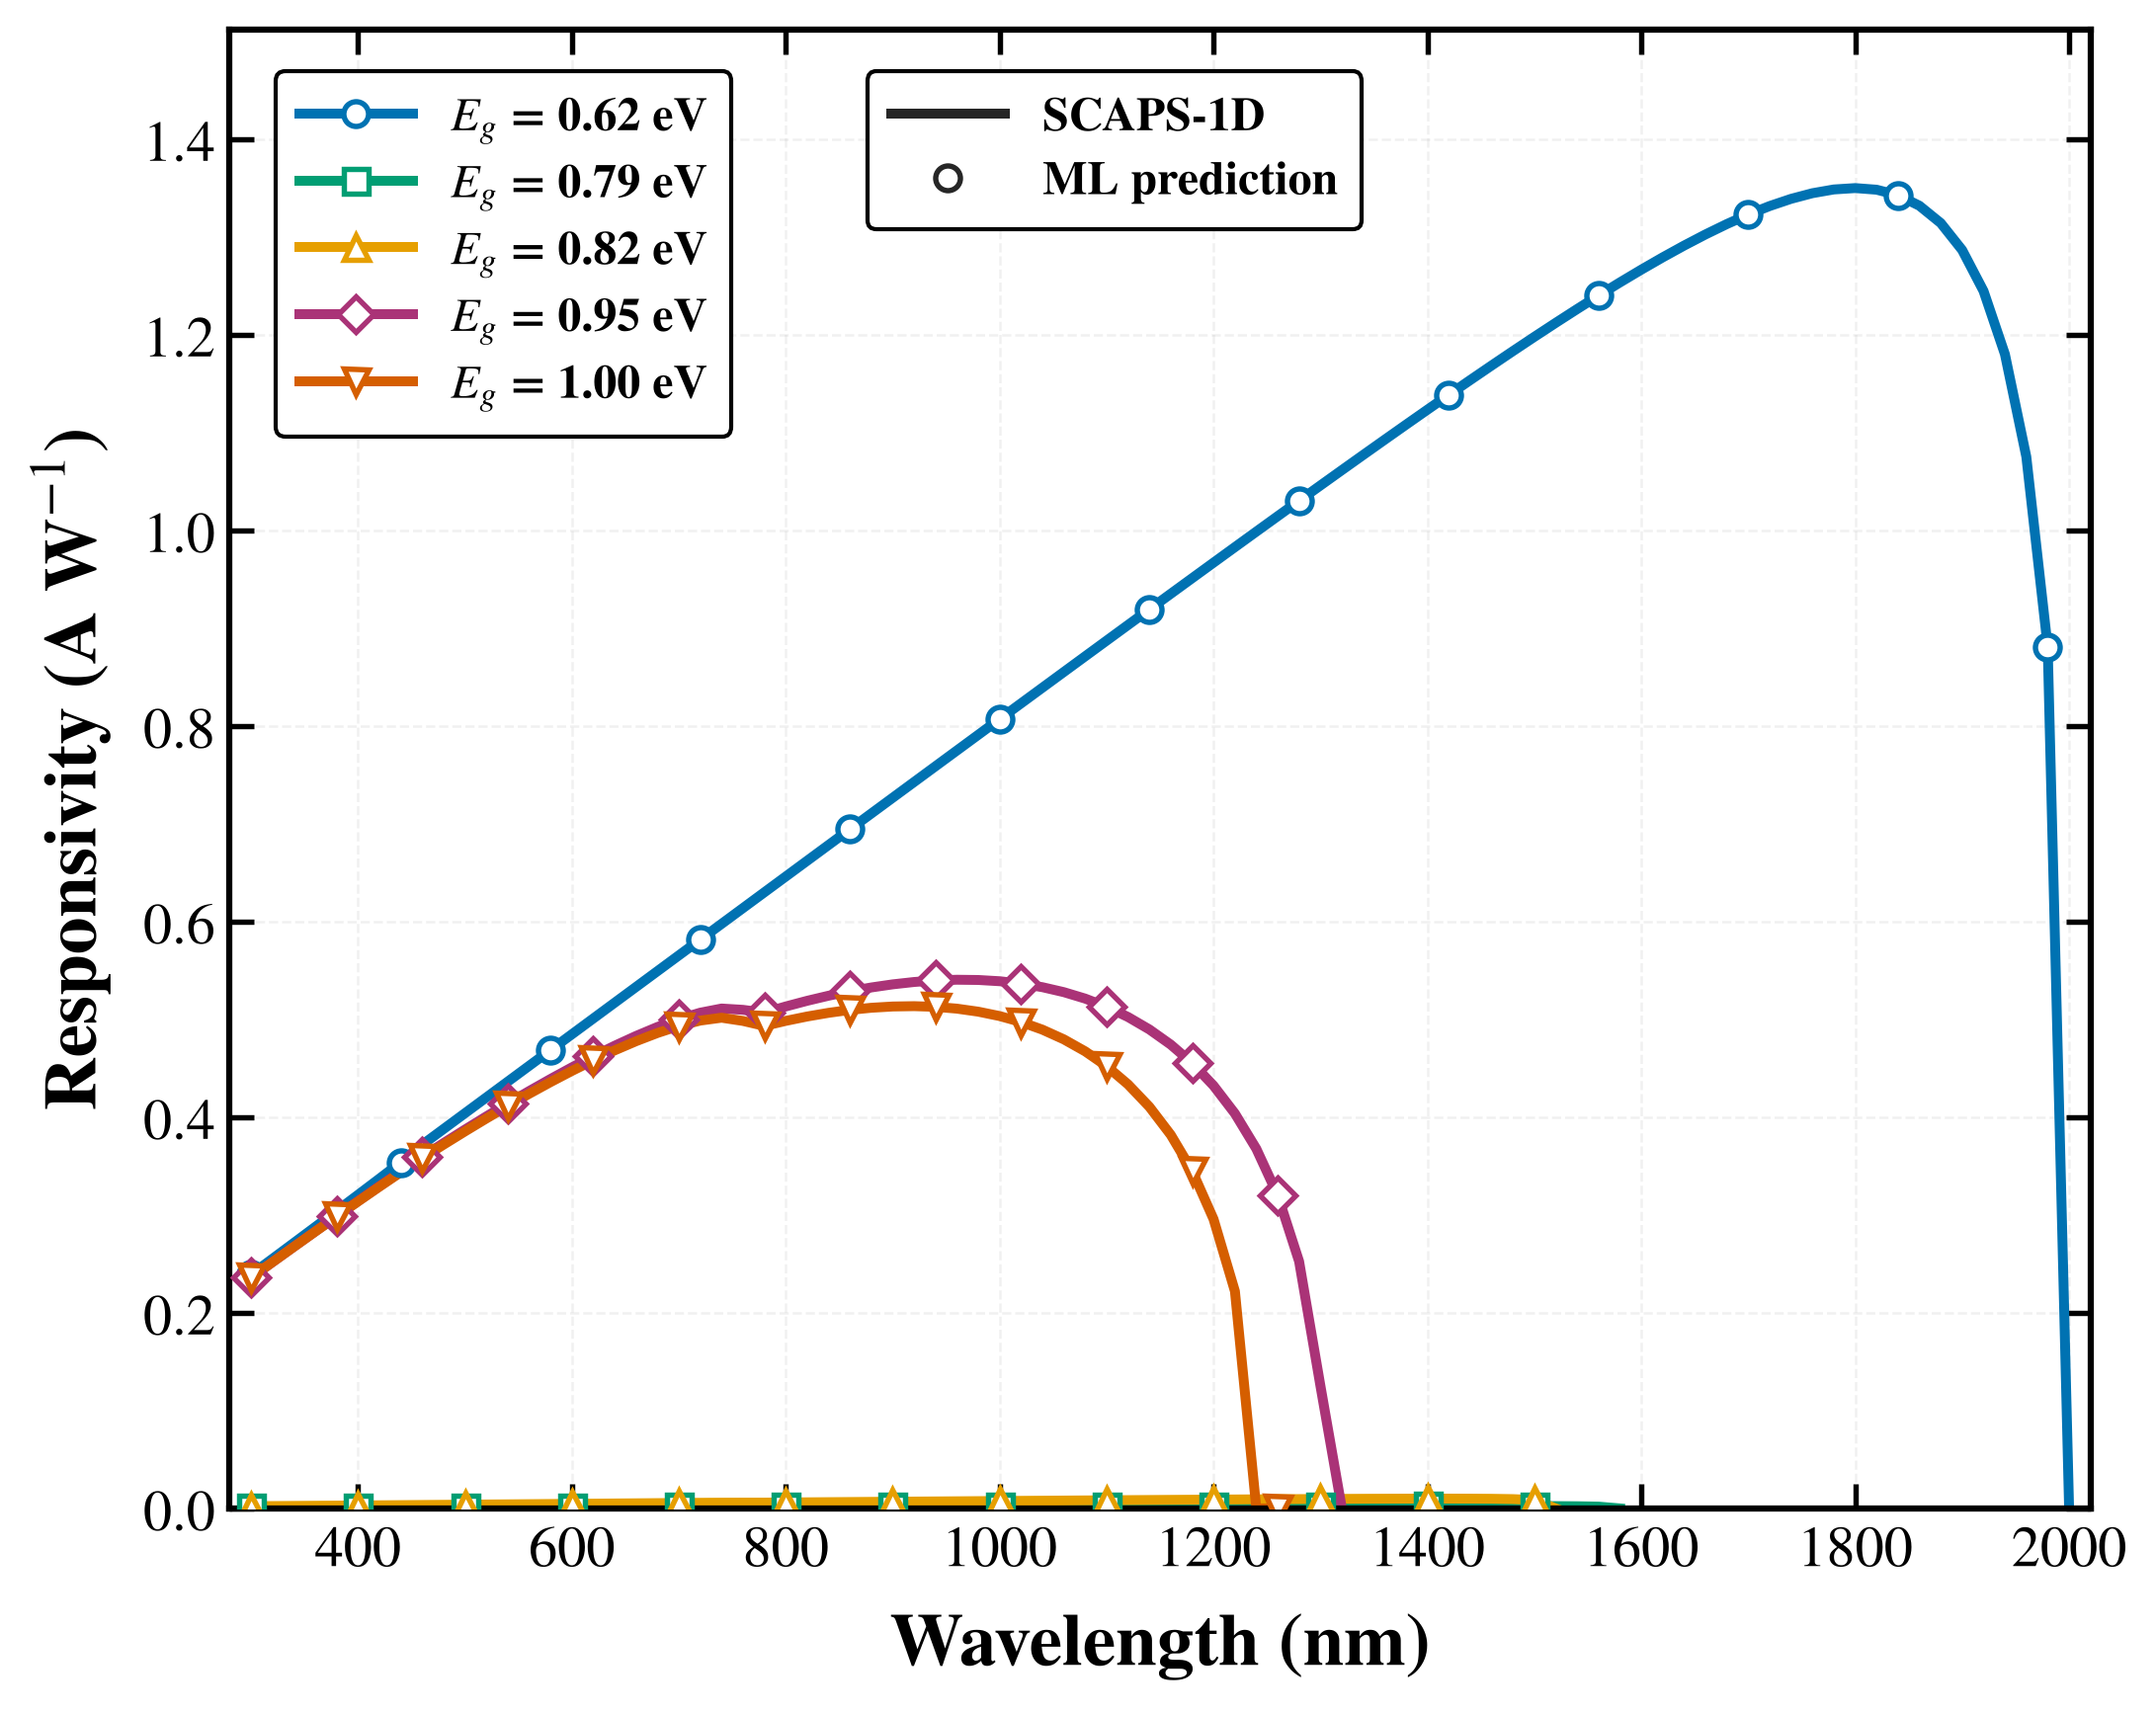

Saved: outputs/Spectral_Detectivity_5Bandgaps.tiff


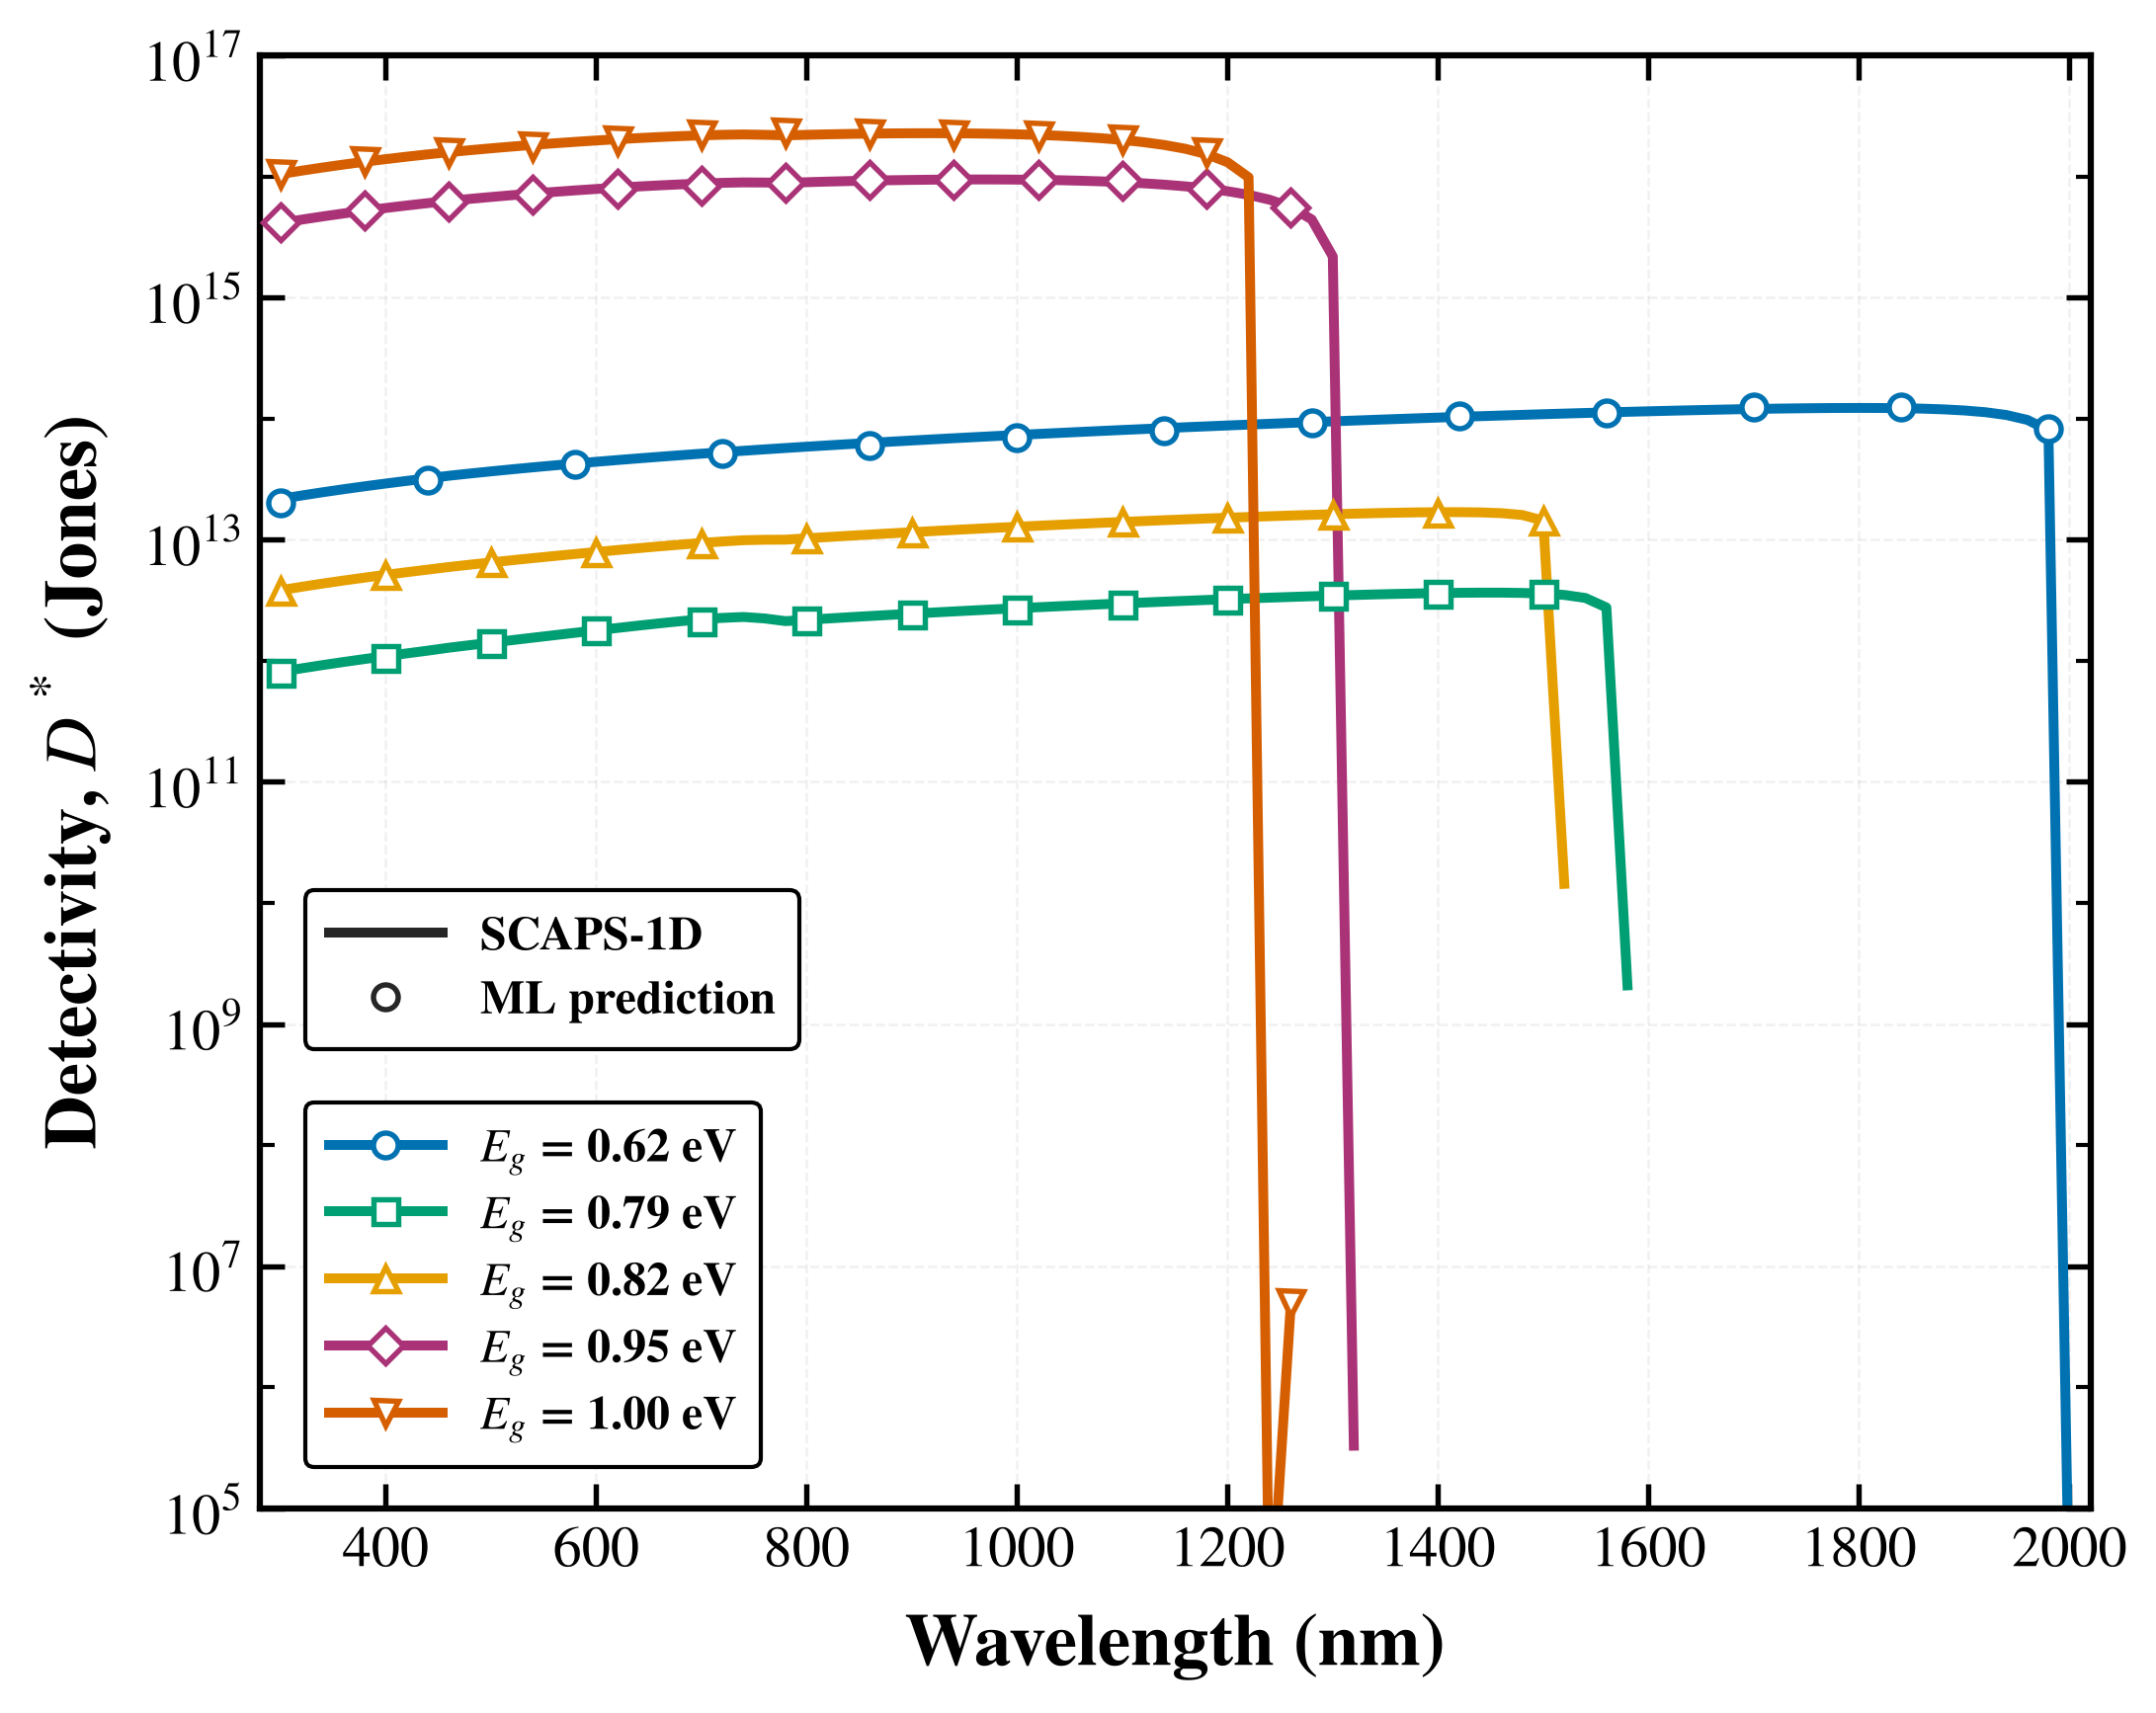

In [12]:
from matplotlib.ticker import FixedLocator

set_plot_style(**{"font.size": 14, "font.weight": "normal", "axes.labelsize": 18, "axes.labelweight": "bold",
                  "xtick.labelsize": 14, "ytick.labelsize": 14, "legend.fontsize": 12, "axes.linewidth": 1.5})

# Colour-blind-safe palette (Okabe-Ito based) with a distinct marker per bandgap, so curves stay
# distinguishable in colour, in greyscale print and where lines overlap.
EG_COLORS  = {0.62: "#0072B2", 0.79: "#009E73", 0.82: "#E69F00", 0.95: "#AA3377", 1.00: "#D55E00"}
EG_MARKERS = {0.62: "o", 0.79: "s", 0.82: "^", 0.95: "D", 1.00: "v"}

LEGEND_KW = dict(frameon=True, facecolor="white", edgecolor="black", framealpha=1.0, borderpad=0.5,
                 handlelength=2.4, labelspacing=0.35)
STYLE_HANDLES = [
    Line2D([0], [0], color="0.15", linewidth=2.4, linestyle="-", label="SCAPS-1D"),
    Line2D([0], [0], color="0.15", linestyle="none", marker="o", markersize=6,
           markerfacecolor="white", markeredgecolor="0.15", markeredgewidth=1.3, label="ML prediction"),
]
BANDGAP_HANDLES = [
    Line2D([0], [0], color=EG_COLORS[eg], linewidth=2.4, marker=EG_MARKERS[eg], markersize=6,
           markerfacecolor="white", markeredgecolor=EG_COLORS[eg], markeredgewidth=1.3,
           label=fr"$E_g$ = {eg:.2f} eV") for eg in BANDGAPS
]


def draw_curves(ax, actual_col, predicted_col, bandgaps, lw=2.4, ms=6.0, n_marks=12):
    # Actual SCAPS-1D spectrum as a solid line, ML prediction as open markers on the same wavelengths
    for eg in bandgaps:
        sub = selected_spectral_df[np.isclose(selected_spectral_df["Eg_round"], eg)].sort_values("Wavelength")
        ax.plot(sub["Wavelength"], sub[actual_col], color=EG_COLORS[eg], linewidth=lw, linestyle="-", zorder=2)
        step = max(len(sub) // n_marks, 1)
        ax.plot(sub["Wavelength"].iloc[::step], sub[predicted_col].iloc[::step], linestyle="none",
                marker=EG_MARKERS[eg], markersize=ms, markerfacecolor="white",
                markeredgecolor=EG_COLORS[eg], markeredgewidth=1.3, zorder=3)


def style_axes(ax, log_y=False, major_len=6, minor_len=3.5, log_major=None, log_minor=None):
    ax.tick_params(axis="both", which="major", direction="in", length=major_len, width=1.3, top=True, right=True)
    ax.tick_params(axis="both", which="minor", direction="in", length=minor_len, width=1.0, top=True, right=True)
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)
    ax.grid(True, which="major", linestyle="--", linewidth=0.6, alpha=0.18)
    if log_y:
        ax.yaxis.set_major_locator(FixedLocator(log_major))
        ax.yaxis.set_major_formatter(LogFormatterMathtext(base=10))
        ax.yaxis.set_minor_locator(FixedLocator(log_minor))
        ax.yaxis.set_minor_formatter(NullFormatter())


def add_legends(ax, bandgap_loc, style_loc):
    # Both legends are anchored in empty regions of the plot so that no curve is hidden
    leg = ax.legend(handles=BANDGAP_HANDLES, prop={"family": "serif", "weight": "bold", "size": 11.5},
                    **bandgap_loc, **LEGEND_KW)
    ax.add_artist(leg)
    ax.legend(handles=STYLE_HANDLES, prop={"family": "serif", "weight": "bold", "size": 11.5}, **style_loc, **LEGEND_KW)


x_min = selected_spectral_df["Wavelength"].min() - 20
x_max = selected_spectral_df["Wavelength"].max() + 20

# ---------------- Responsivity ----------------
fig, ax = plt.subplots(figsize=(7.5, 6.0), dpi=300)
draw_curves(ax, "Responsivity", "Predicted_Responsivity", BANDGAPS)
ax.set_xlim(x_min, x_max)
r_max = np.nanmax(selected_spectral_df[["Responsivity", "Predicted_Responsivity"]].to_numpy())
ax.set_ylim(0, r_max * 1.12)
ax.set_xlabel("Wavelength (nm)", labelpad=7)
ax.set_ylabel(r"Responsivity (A W$^{-1}$)", labelpad=7)
style_axes(ax)
# Empty space above the rising Eg = 0.62 eV curve (upper left)
add_legends(ax, bandgap_loc=dict(loc="upper left", bbox_to_anchor=(0.012, 0.988)),
                style_loc=dict(loc="upper left", bbox_to_anchor=(0.33, 0.988)))

fig.tight_layout()
save_tiff(fig, "Spectral_Responsivity_5Bandgaps.tiff")
plt.show()
plt.close(fig)

# ---------------- Detectivity ----------------
fig, ax = plt.subplots(figsize=(7.5, 6.0), dpi=300)
draw_curves(ax, "Detectivity", "Predicted_Detectivity", BANDGAPS)
ax.set_yscale("log")
ax.set_xlim(x_min, x_max)
# 10^5 to 10^17 with seven labelled decades (every second decade); only the last sub-band-edge points
# of the 0.62 eV (2000 nm) and 1.00 eV (1240 nm) devices fall below 10^5 and run off the lower frame
D_EXP_MIN, D_EXP_MAX = 5, 17
ax.set_ylim(10.0 ** D_EXP_MIN, 10.0 ** D_EXP_MAX)
ax.set_xlabel("Wavelength (nm)", labelpad=7)
ax.set_ylabel(r"Detectivity, $D^*$ (Jones)", labelpad=7)
style_axes(ax, log_y=True,
           log_major=[10.0 ** k for k in range(D_EXP_MIN, D_EXP_MAX + 1, 2)],
           log_minor=[10.0 ** k for k in range(D_EXP_MIN + 1, D_EXP_MAX, 2)])
# Empty space below the plateaus and left of the band-edge drops (lower left), both legends stacked
add_legends(ax, bandgap_loc=dict(loc="lower left", bbox_to_anchor=(0.012, 0.012)),
                style_loc=dict(loc="lower left", bbox_to_anchor=(0.012, 0.30)))   # stacked, clear of the band-edge drops

fig.tight_layout()
save_tiff(fig, "Spectral_Detectivity_5Bandgaps.tiff")
plt.show()
plt.close(fig)


### 4.4 Impurity-based feature importance of the final models

Impurity-based feature importance:


,Responsivity,log10(Detectivity),Average_Importance
VBO,3.176063e-01,0.427379,0.372493
Wavelength,5.351147e-01,0.108775,0.321945
Eg,4.158854e-02,0.277730,0.159659
N_t,1.028489e-05,0.151488,0.075749
t,1.056604e-01,0.009938,0.057799
N_A,1.928006e-05,0.016925,0.008472
Affinity,2.708465e-07,0.004020,0.002010
CBO,2.521510e-07,0.003746,0.001873


Saved: outputs/Feature_Importance_Heatmap_8Features.tiff


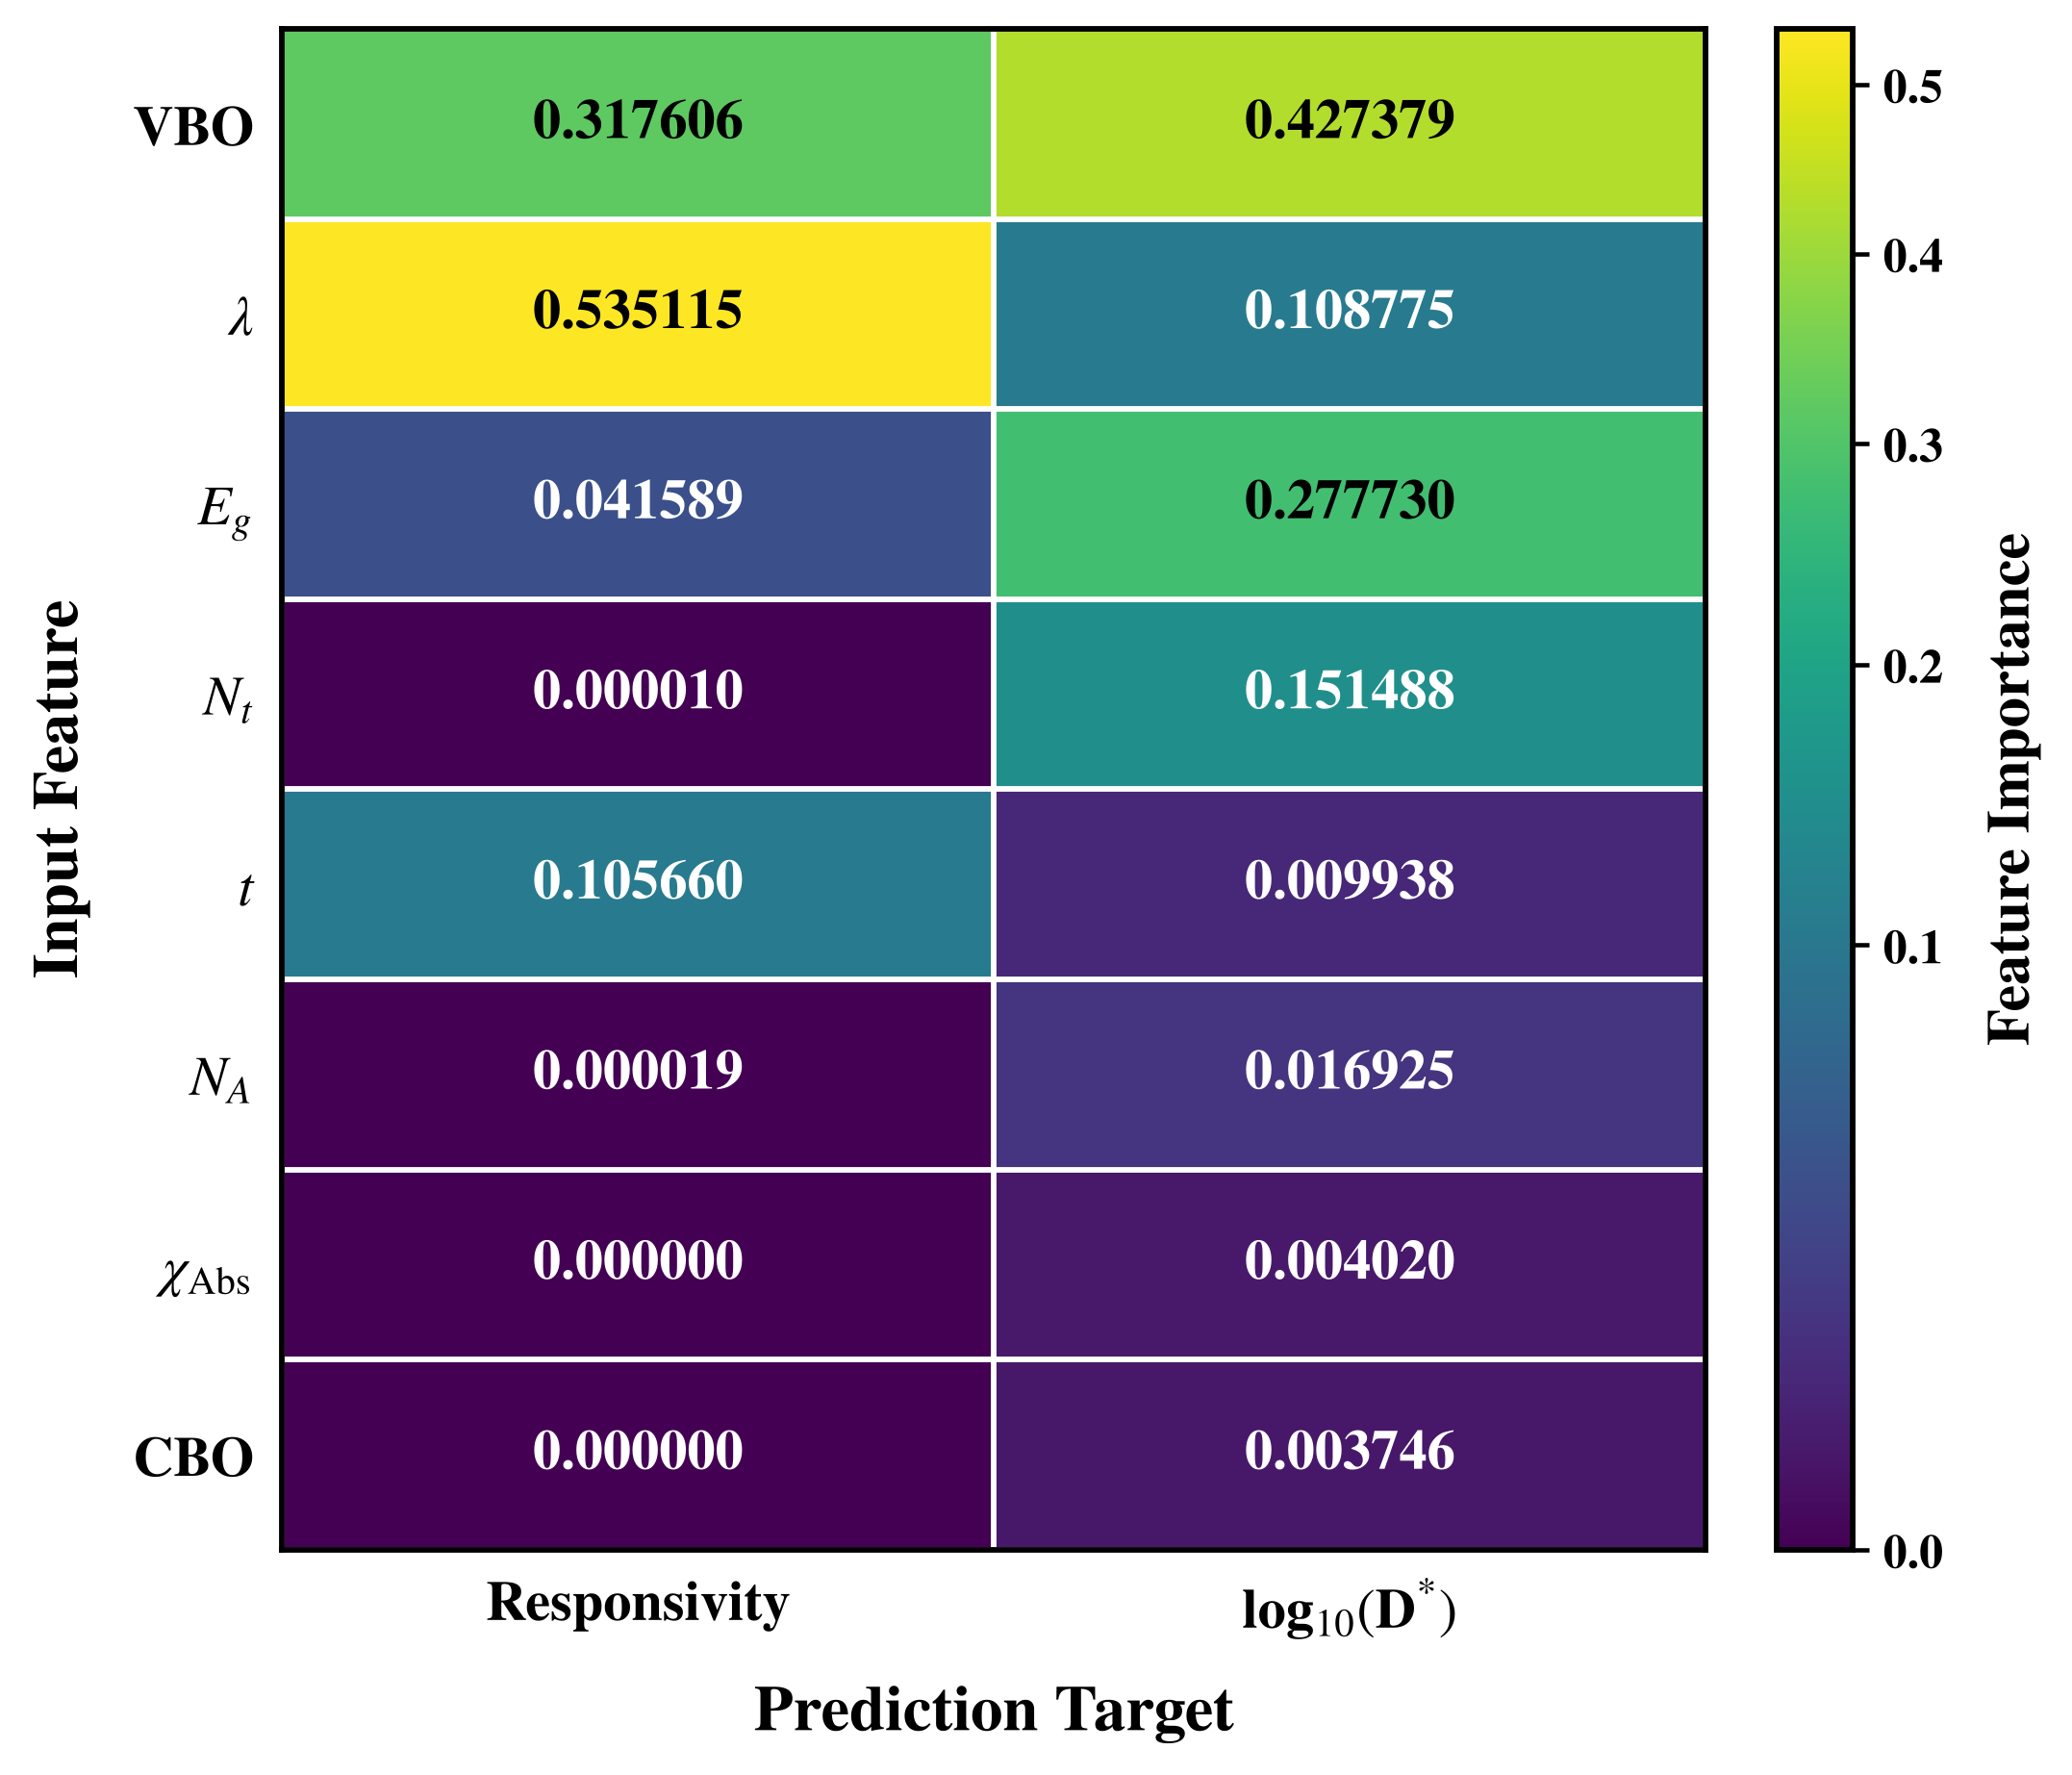

In [13]:
from matplotlib.colors import PowerNorm

importance_df = pd.DataFrame(
    {"Responsivity": final_models["Responsivity"].feature_importances_,
     "log10(Detectivity)": final_models["log10(Detectivity)"].feature_importances_},
    index=FEATURES,
)
importance_df["Average_Importance"] = importance_df[["Responsivity", "log10(Detectivity)"]].mean(axis=1)
importance_df = importance_df.sort_values("Average_Importance", ascending=False)

print("Impurity-based feature importance:")
display(importance_df)

set_plot_style(**{"font.size": 15, "axes.labelsize": 16, "axes.labelweight": "bold",
                  "xtick.labelsize": 14, "ytick.labelsize": 14, "axes.linewidth": 1.4})

heatmap_values = importance_df[["Responsivity", "log10(Detectivity)"]].to_numpy()
row_labels = [FEATURE_LABELS[f] for f in importance_df.index]
column_labels = ["Responsivity", r"$\mathbf{log}_{10}(\mathbf{D}^{*})$"]

fig, ax = plt.subplots(figsize=(7.4, 6.4), dpi=300)
cmap = plt.cm.viridis
max_importance = float(np.nanmax(heatmap_values)) or 1.0
norm = PowerNorm(gamma=0.55, vmin=0, vmax=max_importance)   # gamma < 1 reveals the low-importance cells
image = ax.imshow(heatmap_values, cmap=cmap, norm=norm, aspect="auto")

ax.set_xticks(np.arange(len(column_labels))); ax.set_xticklabels(column_labels, fontweight="bold")
ax.set_yticks(np.arange(len(row_labels)));    ax.set_yticklabels(row_labels, fontweight="bold")
ax.set_xlabel("Prediction Target", labelpad=10)
ax.set_ylabel("Input Feature", labelpad=10)
ax.set_xticks(np.arange(-0.5, len(column_labels), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(row_labels), 1), minor=True)
ax.grid(which="minor", color="white", linewidth=1.4)
ax.tick_params(which="minor", bottom=False, left=False)
ax.tick_params(axis="both", which="major", length=0, pad=7)

for row in range(heatmap_values.shape[0]):
    for col in range(heatmap_values.shape[1]):
        value = heatmap_values[row, col]
        r, g, b, _ = cmap(norm(value))
        text_color = "white" if (0.299 * r + 0.587 * g + 0.114 * b) < 0.50 else "black"
        ax.text(col, row, f"{value:.6f}", ha="center", va="center", color=text_color, fontsize=14, fontweight="bold")

colorbar = fig.colorbar(image, ax=ax, fraction=0.055, pad=0.045)
colorbar.set_label("Feature Importance", fontsize=15, fontweight="bold", labelpad=10)
colorbar.ax.tick_params(labelsize=12, width=1.1, length=4)
for label in colorbar.ax.get_yticklabels():
    label.set_fontweight("bold")
for spine in ax.spines.values():
    spine.set_linewidth(1.4)

fig.tight_layout()
fig.savefig(out_path("Feature_Importance_Heatmap_8Features.png"), dpi=600, bbox_inches="tight")
save_tiff(fig, "Feature_Importance_Heatmap_8Features.tiff")
plt.show()
plt.close(fig)

### 4.5 Global SHAP importance with exact TreeSHAP audit

A bandgap-balanced sample of the test set (20 devices per bandgap, 10 wavelengths per device, 1,000 rows) is explained
with approximate TreeSHAP. A nested sub-sample (5 devices per bandgap, 2 wavelengths each, 50 rows) is additionally
explained with exact TreeSHAP to check that the approximate ranking is reliable (rank correlation and top-3 agreement)
and that the exact values satisfy additivity.

In [14]:
STRUCTURES_PER_EG, ROWS_PER_STRUCTURE = 20, 10        # global sample: 5 x 20 x 10 = 1000 rows
AUDIT_STRUCTURES_PER_EG, AUDIT_ROWS_PER_STRUCTURE = 5, 2   # exact audit: 5 x 5 x 2 = 50 rows
RHO_THRESHOLD, MIN_TOP3_OVERLAP = 0.90, 2


def balanced_sample(source_df, structures_per_eg, rows_per_structure, seed):
    parts = []
    for i, eg in enumerate(BANDGAPS):
        eg_df = source_df[np.isclose(source_df["Eg"], eg)]
        ids = np.sort(eg_df["Structure_ID"].unique())
        rng = np.random.default_rng(seed + i)
        for sid in rng.choice(ids, size=min(structures_per_eg, len(ids)), replace=False):
            rows = eg_df[eg_df["Structure_ID"] == sid].sort_values("Wavelength").reset_index(drop=True)
            positions = np.unique(np.linspace(0, len(rows) - 1, min(rows_per_structure, len(rows)), dtype=int))
            parts.append(rows.iloc[positions])
    return pd.concat(parts, ignore_index=True).sort_values(["Eg", "Structure_ID", "Wavelength"]).reset_index(drop=True)


global_sample_df = balanced_sample(test_df, STRUCTURES_PER_EG, ROWS_PER_STRUCTURE, RANDOM_STATE)
audit_sample_df  = balanced_sample(global_sample_df, AUDIT_STRUCTURES_PER_EG, AUDIT_ROWS_PER_STRUCTURE, RANDOM_STATE + 1000)
X_global = global_sample_df[FEATURES].astype(np.float32)
X_audit  = audit_sample_df[FEATURES].astype(np.float32)
print(f"Global sample: {len(X_global):,} rows | Audit sample: {len(X_audit):,} rows")

global_shap_values, importance_records, audit_records = {}, [], []

for target, model in final_models.items():
    t0 = time.time()
    explainer = shap.TreeExplainer(model, feature_perturbation="tree_path_dependent", model_output="raw")

    shap_global = normalize_shap_array(explainer.shap_values(X_global, approximate=True, check_additivity=False))
    shap_audit_approx = normalize_shap_array(explainer.shap_values(X_audit, approximate=True, check_additivity=False))
    t1 = time.time()
    shap_audit_exact = normalize_shap_array(explainer.shap_values(X_audit, approximate=False, check_additivity=True))
    t2 = time.time()
    assert shap_global.shape == X_global.shape and shap_audit_exact.shape == X_audit.shape
    global_shap_values[target] = shap_global          # kept for the beeswarm plots

    global_importance = np.abs(shap_global).mean(axis=0)
    approx_importance = np.abs(shap_audit_approx).mean(axis=0)
    exact_importance  = np.abs(shap_audit_exact).mean(axis=0)

    # Additivity: expected value + sum of exact SHAP values must reproduce the prediction
    reconstructed = expected_value_scalar(explainer) + shap_audit_exact.sum(axis=1)
    max_additivity_error = np.max(np.abs(model.predict(X_audit) - reconstructed))

    # Ranking stability between approximate and exact SHAP on the audit rows
    approx_ranks = pd.Series(approx_importance, index=FEATURES).rank(ascending=False)
    exact_ranks  = pd.Series(exact_importance, index=FEATURES).rank(ascending=False)
    spearman_rho = approx_ranks.corr(exact_ranks, method="pearson")
    approx_top3 = [FEATURES[i] for i in np.argsort(approx_importance)[-3:][::-1]]
    exact_top3  = [FEATURES[i] for i in np.argsort(exact_importance)[-3:][::-1]]
    top3_overlap = len(set(approx_top3) & set(exact_top3))
    audit_passed = spearman_rho >= RHO_THRESHOLD and top3_overlap >= MIN_TOP3_OVERLAP

    importance_records += [{"Target": target, "Feature": f, "MeanAbsSHAP": v, "Importance_Percent": 100 * v / global_importance.sum()}
                           for f, v in zip(FEATURES, global_importance)]
    audit_records.append({"Target": target, "Global_Rows": len(X_global), "Audit_Rows": len(X_audit),
                          "Spearman_Rho": spearman_rho, "Top3_Overlap": top3_overlap,
                          "Approximate_Top3": ", ".join(approx_top3), "Exact_Top3": ", ".join(exact_top3),
                          "Maximum_Additivity_Error": max_additivity_error,
                          "Approximate_Time_min": (t1 - t0) / 60, "Exact_Time_min": (t2 - t1) / 60,
                          "Audit_Passed": audit_passed})
    print(f"{target:<20} rho = {spearman_rho:.4f} | top-3 overlap = {top3_overlap}/3 | "
          f"additivity error = {max_additivity_error:.2e} | passed = {audit_passed} | {(time.time() - t0) / 60:.1f} min")

    del explainer, shap_audit_approx, shap_audit_exact
    gc.collect()

global_shap_importance_df = pd.DataFrame(importance_records)
audit_summary_df = pd.DataFrame(audit_records)

print("\nGlobal SHAP importance:")
display(global_shap_importance_df.sort_values(["Target", "MeanAbsSHAP"], ascending=[True, False]).reset_index(drop=True))
print("\nExact TreeSHAP audit:")
display(audit_summary_df)

failed = audit_summary_df.loc[~audit_summary_df["Audit_Passed"], "Target"].tolist()
if failed:
    raise RuntimeError(f"SHAP audit failed for {failed}. Increase the audit sample size.")

Global sample: 1,000 rows | Audit sample: 50 rows


Responsivity         rho = 0.9762 | top-3 overlap = 3/3 | additivity error = 9.88e-15 | passed = True | 0.0 min


log10(Detectivity)   rho = 0.9524 | top-3 overlap = 3/3 | additivity error = 1.64e-13 | passed = True | 0.0 min

Global SHAP importance:


,Target,Feature,MeanAbsSHAP,Importance_Percent
0,Responsivity,Wavelength,0.185991,48.684800
1,Responsivity,VBO,0.099927,26.156715
2,Responsivity,t,0.055978,14.652796
3,Responsivity,Eg,0.039011,10.211583
4,Responsivity,N_A,0.000551,0.144305
5,Responsivity,N_t,0.000476,0.124668
6,Responsivity,Affinity,0.000063,0.016438
7,Responsivity,CBO,0.000033,0.008696
8,log10(Detectivity),Eg,0.649620,27.976840
9,log10(Detectivity),VBO,0.624170,26.880781



Exact TreeSHAP audit:


,Target,Global_Rows,Audit_Rows,Spearman_Rho,Top3_Overlap,Approximate_Top3,Exact_Top3,Maximum_Additivity_Error,Approximate_Time_min,Exact_Time_min,Audit_Passed
0,Responsivity,1000,50,0.976190,3,"Wavelength, VBO, Eg","Wavelength, Eg, VBO",9.883587e-15,0.000102,0.010029,True
1,log10(Detectivity),1000,50,0.952381,3,"Wavelength, VBO, Eg","Wavelength, Eg, VBO",1.636469e-13,0.000331,0.014869,True


Saved: outputs/SHAP_Global_Bar_Responsivity.tiff


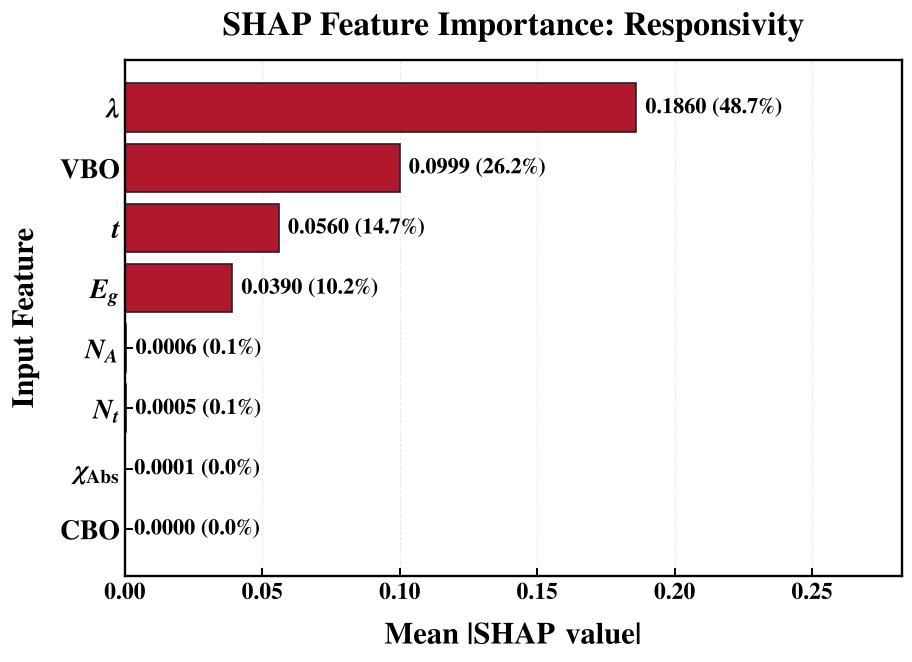

Saved: outputs/SHAP_Global_Bar_log10_Detectivity.tiff


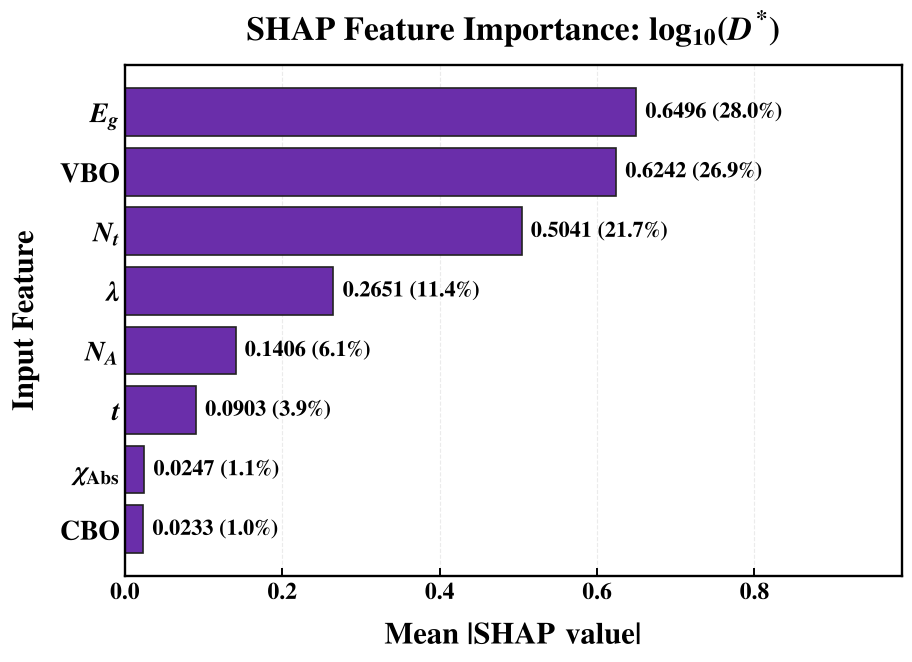

In [15]:
set_plot_style(**{"font.size": 16, "font.weight": "bold", "axes.labelsize": 22, "axes.labelweight": "bold",
                  "axes.titlesize": 24, "axes.titleweight": "bold", "xtick.labelsize": 17, "ytick.labelsize": 20,
                  "axes.linewidth": 1.7})


def plot_global_shap_bar(target, title, color, filename):
    plot_df = (global_shap_importance_df[global_shap_importance_df["Target"] == target]
               .sort_values("MeanAbsSHAP").reset_index(drop=True))
    labels = [FEATURE_LABELS[f] for f in plot_df["Feature"]]
    values = plot_df["MeanAbsSHAP"].to_numpy()
    percentages = plot_df["Importance_Percent"].to_numpy()

    fig, ax = plt.subplots(figsize=(9.4, 6.9))
    bars = ax.barh(labels, values, color=color, edgecolor="#222222", linewidth=1.2, height=0.80)
    ax.set_title(title, pad=18)
    ax.set_xlabel(r"Mean $|\mathrm{SHAP\ value}|$", labelpad=12)
    ax.set_ylabel("Input Feature", labelpad=14)
    ax.tick_params(axis="both", direction="in", length=6, width=1.4)
    for tick in ax.get_xticklabels() + ax.get_yticklabels():
        tick.set_fontweight("bold")
    ax.grid(axis="x", linestyle="--", linewidth=0.8, alpha=0.25)
    ax.set_axisbelow(True)

    maximum = max(float(values.max()), 1e-12)
    ax.set_xlim(0, maximum * 1.52)
    for bar, value, pct in zip(bars, values, percentages):
        ax.text(value + maximum * 0.018, bar.get_y() + bar.get_height() / 2, f"{value:.4f} ({pct:.1f}%)",
                va="center", ha="left", fontsize=16, fontweight="bold")
    for spine in ax.spines.values():
        spine.set_linewidth(1.7)

    fig.tight_layout()
    save_tiff(fig, filename)
    plt.show()
    plt.close(fig)


plot_global_shap_bar("Responsivity", "SHAP Feature Importance: Responsivity", "#B2182B", "SHAP_Global_Bar_Responsivity.tiff")
plot_global_shap_bar("log10(Detectivity)", r"SHAP Feature Importance: $\mathbf{log}_{10}(D^{*})$", "#6A2EAA",
                     "SHAP_Global_Bar_log10_Detectivity.tiff")

### 4.6 SHAP beeswarm plots (same 1,000-row balanced sample)

Saved: outputs/SHAP_Beeswarm_Responsivity.tiff


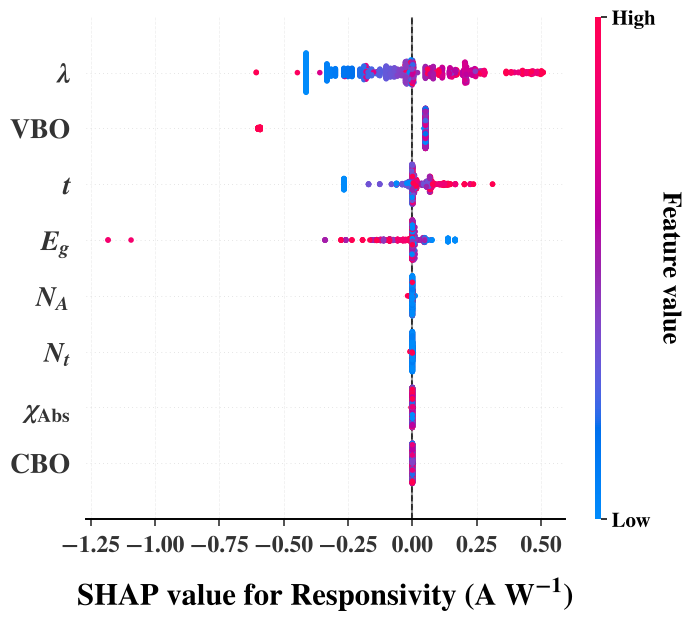

Saved: outputs/SHAP_Beeswarm_log10_Detectivity.tiff


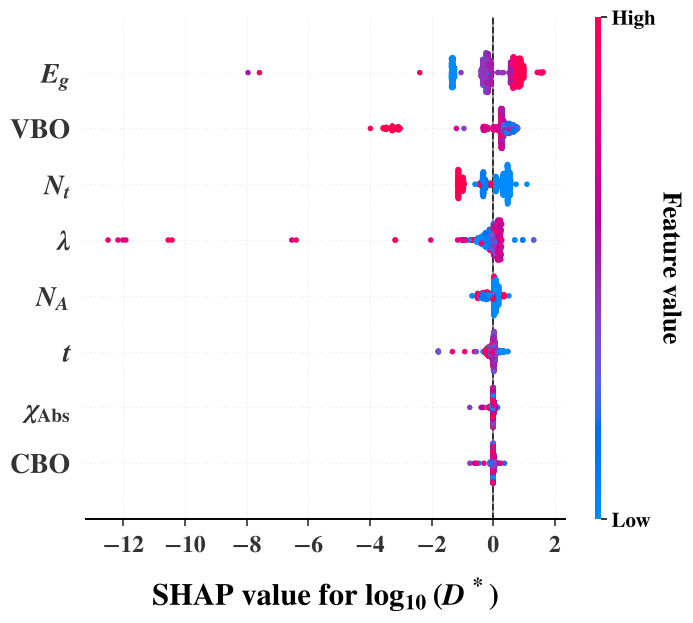

In [16]:
set_plot_style(**{"font.size": 16, "font.weight": "bold", "axes.labelsize": 22, "axes.labelweight": "bold",
                  "axes.titlesize": 22, "axes.titleweight": "bold", "xtick.labelsize": 17, "ytick.labelsize": 20,
                  "axes.linewidth": 1.6, "savefig.dpi": 600})

X_beeswarm = X_global.copy()
beeswarm_labels = [FEATURE_LABELS_MATH[f] for f in FEATURES]


def plot_beeswarm(target, x_label, filename):
    plt.close("all")
    np.random.seed(RANDOM_STATE)     # fixes the vertical jitter of the beeswarm
    shap.summary_plot(shap_values=global_shap_values[target], features=X_beeswarm, feature_names=beeswarm_labels,
                      plot_type="dot", max_display=len(FEATURES), sort=True, show=False, color_bar=True,
                      plot_size=(8.8, 6.2))
    fig = plt.gcf()
    ax = fig.axes[0]

    ax.set_title("")
    ax.set_xlabel(x_label, fontsize=22, fontweight="bold", labelpad=14)
    ax.axvline(0, color="black", linestyle="--", linewidth=1.2, alpha=0.85, zorder=0)
    ax.grid(axis="x", linestyle="--", linewidth=0.6, alpha=0.18)
    ax.set_axisbelow(True)
    ax.tick_params(axis="both", which="major", direction="out", length=5, width=1.2, pad=6)
    for label in ax.get_xticklabels():
        label.set_fontfamily("serif"); label.set_fontweight("bold"); label.set_fontsize(17)
    for label in ax.get_yticklabels():
        label.set_fontfamily("serif"); label.set_fontweight("bold"); label.set_fontsize(20)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.4)
    ax.spines["bottom"].set_linewidth(1.4)

    if len(fig.axes) > 1:                           # colour bar
        cax = fig.axes[-1]
        cax.set_ylabel("Feature value", fontsize=19, fontweight="bold", rotation=270, labelpad=20)
        cax.tick_params(labelsize=15, width=1.1, length=4)
        cax.set_yticklabels([t.get_text() for t in cax.get_yticklabels()], fontweight="bold", fontsize=15, fontfamily="serif")

    fig.set_size_inches(8.8, 6.2)
    fig.subplots_adjust(left=0.22, right=0.90, bottom=0.17, top=0.98)
    save_tiff(fig, filename)
    plt.show()
    plt.close(fig)


plot_beeswarm("Responsivity", r"SHAP value for Responsivity (A W$^{-1}$)", "SHAP_Beeswarm_Responsivity.tiff")
plot_beeswarm("log10(Detectivity)", r"SHAP value for $\log_{10}(D^*)$", "SHAP_Beeswarm_log10_Detectivity.tiff")

## 5. Export summary tables

In [17]:
tables = {
    "Model_Selection_CV_and_Test_Benchmark.csv": benchmark_df,
    "Model_Selection_CV_All_Folds.csv":    cv_folds_df,
    "Model_Comparison_Test_Metrics.csv":   test_metrics_df,
    "Model_Comparison_Train_Metrics.csv":  train_metrics_df,
    "Final_Model_Train_Test_Metrics.csv":  final_metrics,
    "Split_Bandgap_Balance.csv":           split_balance.round(4),
    "Spectral_Validation_Devices.csv":     selected_structures,
    "Spectral_Validation_Metrics.csv":     bandgap_metrics,
    "Feature_Importance.csv":              importance_df.rename_axis("Feature"),
    "SHAP_Global_Importance.csv":          global_shap_importance_df,
    "SHAP_Exact_Audit_Summary.csv":        audit_summary_df,
}
for filename, table in tables.items():
    table.to_csv(out_path(filename), index=isinstance(table.index, pd.MultiIndex) or table.index.name is not None)

print(f"Files written to '{OUTPUT_DIR}/':")
for name in sorted(os.listdir(OUTPUT_DIR)):
    print("  ", name)

Files written to 'outputs/':
   Actual_vs_Predicted_Responsivity.tiff
   Actual_vs_Predicted_log10_Detectivity.tiff
   Best_Model_Responsivity.pkl
   Best_Model_log10_Detectivity.pkl
   Feature_Importance.csv
   Feature_Importance_Heatmap_8Features.png
   Feature_Importance_Heatmap_8Features.tiff
   Final_Model_Train_Test_Metrics.csv
   Model_Comparison_Test_Metrics.csv
   Model_Comparison_Train_Metrics.csv
   Model_Selection_CV_All_Folds.csv
   Model_Selection_CV_and_Test_Benchmark.csv
   SHAP_Beeswarm_Responsivity.tiff
   SHAP_Beeswarm_log10_Detectivity.tiff
   SHAP_Exact_Audit_Summary.csv
   SHAP_Global_Bar_Responsivity.tiff
   SHAP_Global_Bar_log10_Detectivity.tiff
   SHAP_Global_Importance.csv
   Spectral_Detectivity_5Bandgaps.tiff
   Spectral_Responsivity_5Bandgaps.tiff
   Spectral_Validation_Devices.csv
   Spectral_Validation_Metrics.csv
   Split_Bandgap_Balance.csv
